# MECG 7780 — Time Serial Dependency Modeling
## A complete Python research walkthrough

**Question:** How accurately and efficiently can past vibration predict the next
normalized sample under variable speed, and what do prediction residuals reveal?

This notebook follows the actual saved experiment, not an imagined worked result.
It audits the MATLAB records, constructs causal windows, explains fitted linear
and nonlinear models, reloads every checkpoint, compares common-index validation
metrics, and demonstrates diagnostic mathematics. It does **not** invent a held-out
test set, physical speed units, health-state labels, or physical fault severity.
It now incorporates all 200 real candidate-fault records supplied in 20 verified
MATLAB-struct parts; the partition preserves complete recording boundaries.

**Read alongside:** [Study companion](../docs/COMPREHENSIVE_STUDY_COMPANION.md),
[final report](../reports/PROJECT_FINAL_REPORT.md),
[reproduction instructions](../docs/reproduce_windows_linux_macos.md).

**Safe execution:** install the project dependencies, place `sigtrain.mat` and
`sigvalid.mat` in `data/raw` and all 20 fault parts plus their manifest in
`data/raw/sigfault1_parts`, retain the packaged `models/` and `experiments/` files,
then use **Restart Kernel → Run All**. Default mode loads checkpoints and performs
small illustrative computations. It does not retrain the suite or overwrite raw
inputs. Full retraining is a separate `python reproduce_all.py --level full` command.

**Course brief:** the updated PDF is authoritative: 8-minute progress, 12-minute
final. Progress weights are 4/6/8/2%; final weights are 16/24/30/10%. Its progress
2026 date conflicts with final 2025 dates; final due dates remain unconfirmed.

## Contents

1. Environment and provenance
2. Input audit, normalization and units
3. Sampling, spectra and variable speed
4. Strictly causal windows and fair evaluation
5. Baselines and fitted checkpoints
6. GRU, TCN and speed-conditioned models
7. Common-index validation results and efficiency
8. Residual statistics and uncertainty
9. Angular resampling, correlated kurtosis and PMI
10. Full 200-record fault-candidate analysis, reproduction and conclusions

The walkthrough uses production modules in `src/rotmach`; the small synthetic
examples teach conventions rather than provide machinery-fault ground truth.

## 1. Environment and provenance

We choose a project root by inspecting the current folder, avoiding a hardcoded
Windows or cloud path. Small CPU thread counts reduce scheduling overhead for
these compact models. The supplied normalized vibration is dimensionless; speed
has an unidentified source unit. A GPU is optional and no GPU timing is claimed.

In [1]:
from pathlib import Path
import sys, os, json, platform, tempfile
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "rotmach-mpl-cache"))
os.environ.setdefault("XDG_CACHE_HOME", str(Path(tempfile.gettempdir()) / "rotmach-font-cache"))
ROOT = Path.cwd().resolve()
if not (ROOT / "src/rotmach").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/rotmach").exists(), "Run inside the released project or notebooks folder"
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import scipy
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
torch.set_num_threads(2)
QUICK_MODE = True  # checkpoint inference; full training is deliberately a separate CLI
print({"python": platform.python_version(), "numpy": np.__version__,
       "scipy": scipy.__version__, "torch": torch.__version__,
       "device": "CPU", "threads": torch.get_num_threads()})

{'python': '3.12.14', 'numpy': '2.3.5', 'scipy': '1.17.0', 'torch': '2.15.0+cpu', 'device': 'CPU', 'threads': 2}


### Provenance means more than a filename

An SHA256 checksum identifies the bytes that produced an experiment. The manifest
states which input files were actually inspected and which were absent. This
prevents a prior examination of another dataset version from being reported as
current evidence. The original fault monolith exceeded the transfer limit; the
user subsequently provided 20 complete-record parts. Their per-file checksums and
logical content are independently verified, rather than inferring that a byte hash
of the inaccessible original monolith has been independently recomputed.

In [2]:
from rotmach.io_matlab import load_records, sha256
manifest = json.loads((ROOT / "data/manifest.json").read_text())
display(pd.DataFrame(manifest)[["name", "size_bytes", "sha256", "availability"]].fillna("—"))
for item in manifest:
    if "sha256" in item:
        assert sha256(ROOT / item["location"]) == item["sha256"]
print("Available raw input checksums verified.")

,name,size_bytes,sha256,availability
0,MECG 7780 Course Project - Score Allocation Up...,169390.0,22df5fb9c353c16d40ccd8f4cb000a095608969b49dad0...,available
1,fdt_featcal.m,4115.0,6c1206b0cb7e1098b6b9b52cf437e2ba5097e05334e9c0...,available
2,sigtrain.mat,737025.0,47d23efd20d86ed9e67181a96c9b73039a79a874e0d9ae...,available
3,sigvalid.mat,736973.0,07013d4b17d7ae6fc740365264def53882664a49fde278...,available
4,sigfault1_part_001.mat,7347291.0,a5554e18ff68f8fe50b48d6020ea818d279aa7ceed1f55...,available
5,sigfault1_part_002.mat,7346281.0,a1d96948943512734ad5779dd2acfa2d9e0cfdcfa88702...,available
6,sigfault1_part_003.mat,7345482.0,f1cccc900b8b0a0cd29e0deed493dee367ed963484ee08...,available
7,sigfault1_part_004.mat,7346358.0,b9f5d5763838dda8770e1dc4bcf250b2698fcd95e4ad54...,available
8,sigfault1_part_005.mat,7346786.0,b133ebde2b89248dc1851bbfc484bc76d5a28a03703675...,available
9,sigfault1_part_006.mat,7346063.0,0e085b9c47ce187d561082550a3bb39bd1555eeaf3676a...,available


Available raw input checksums verified.


## 2. Input audit, normalization and units

`load_records` preserves one dictionary per recording. It refuses missing fields,
invalid vector shapes, nonfinite numbers, unequal sample lengths, nonpositive
sampling/speed, and inconsistent timestamps. The fault-part loader preserves all
200 independently inspected records instead of flattening them into one sequence.
Current files use MATLAB v5-family
storage; unsupported v7.3/HDF5 input fails explicitly instead of being misread.

In [3]:
train = load_records(ROOT / "data/raw/sigtrain.mat")[0]
valid = load_records(ROOT / "data/raw/sigvalid.mat")[0]
audit = json.loads((ROOT / "reports/data_audit.json").read_text())
display(pd.DataFrame({k: audit[k] for k in ["sigtrain", "sigvalid"]}).T)
print("Train fields:", sorted(train))
assert train["N"] == valid["N"] == 24000
assert train["fs"] == valid["fs"] == 3200
print("Exact durations N/fs:", train["N"]/train["fs"], valid["N"]/valid["fs"], "s")

,N,fs,duration_samples_s,time_first,time_last,x_mean,x_std,speed_min,speed_max,normalized_speed_min,normalized_speed_max,xmean_metadata,xstd_metadata,empirical_raw_mean,empirical_raw_std,x_reconstruction_max_error,speed_reconstruction_max_error
sigtrain,24000,3200.0,7.5,0.000313,7.5,-0.00308,1.040098,124.32284,167.333518,0.005739,0.999904,"[0.0026221941677904226, 0.0, 0.0]","[0.42517293168840065, 0.0, 0.0]",0.001313,0.442222,0.0,0.0
sigvalid,24000,3200.0,7.5,0.000313,7.5,-0.011851,1.047268,124.335179,167.322539,0.006024,0.999651,"[0.0026221941677904226, 0.00047511172064736986...","[0.42517293168840065, 0.36319708540032314, 0.4...",-0.002417,0.44527,0.0,0.0


Train fields: ['N', 'fs', 'record_id', 'spd', 'spdmax', 'spdmin', 'spdnorm', 't', 'x', 'xmean', 'xraw', 'xstd']
Exact durations N/fs: 7.5 7.5 s


### Stored scaling and empirical moments answer different questions

The file supplies \(x=(x^{raw}-\mu_*)/\sigma_*\). Its stored \(\mu_*\) and
\(\sigma_*\) are **not** necessarily the mean and standard deviation of this
24,000-sample trace. Only their relevant first entries have an established role;
other metadata entries receive no invented interpretation. We use `x` as provided
and do not normalize each record independently, which could remove useful amplitude
changes. Speed normalization is also reused without clipping values outside [0,1].

In [4]:
normalization_rows = []
for name, record in [("train", train), ("valid", valid)]:
    mu, sd = record["xmean"][0], record["xstd"][0]
    reconstructed = (record["xraw"] - mu) / sd
    speed_reconstructed = ((record["spd"] - record["spdmin"]) /
                           (record["spdmax"] - record["spdmin"]))
    assert np.allclose(reconstructed, record["x"], atol=1e-12)
    assert np.allclose(speed_reconstructed, record["spdnorm"], atol=1e-12)
    normalization_rows.append(dict(record=name, stored_mu=mu, stored_sd=sd,
        measured_raw_mean=record["xraw"].mean(), measured_raw_sd=record["xraw"].std(),
        max_reconstruction_error=np.max(np.abs(reconstructed-record["x"]))))
display(pd.DataFrame(normalization_rows))

,record,stored_mu,stored_sd,measured_raw_mean,measured_raw_sd,max_reconstruction_error
0,train,0.002622,0.425173,0.001313,0.442222,0.0
1,valid,0.002622,0.425173,-0.002417,0.445270,0.0


The supplied training and validation speed histories are very similar. A high
correlation limits the range of operating-history transfer tested here, but it
does not by itself prove target leakage or duplicate vibration measurements.

speed_pearson                         1.000000
vibration_pearson                     0.041291
valid_speed_outside_train_fraction    0.000000
Name: Measured comparison, dtype: float64

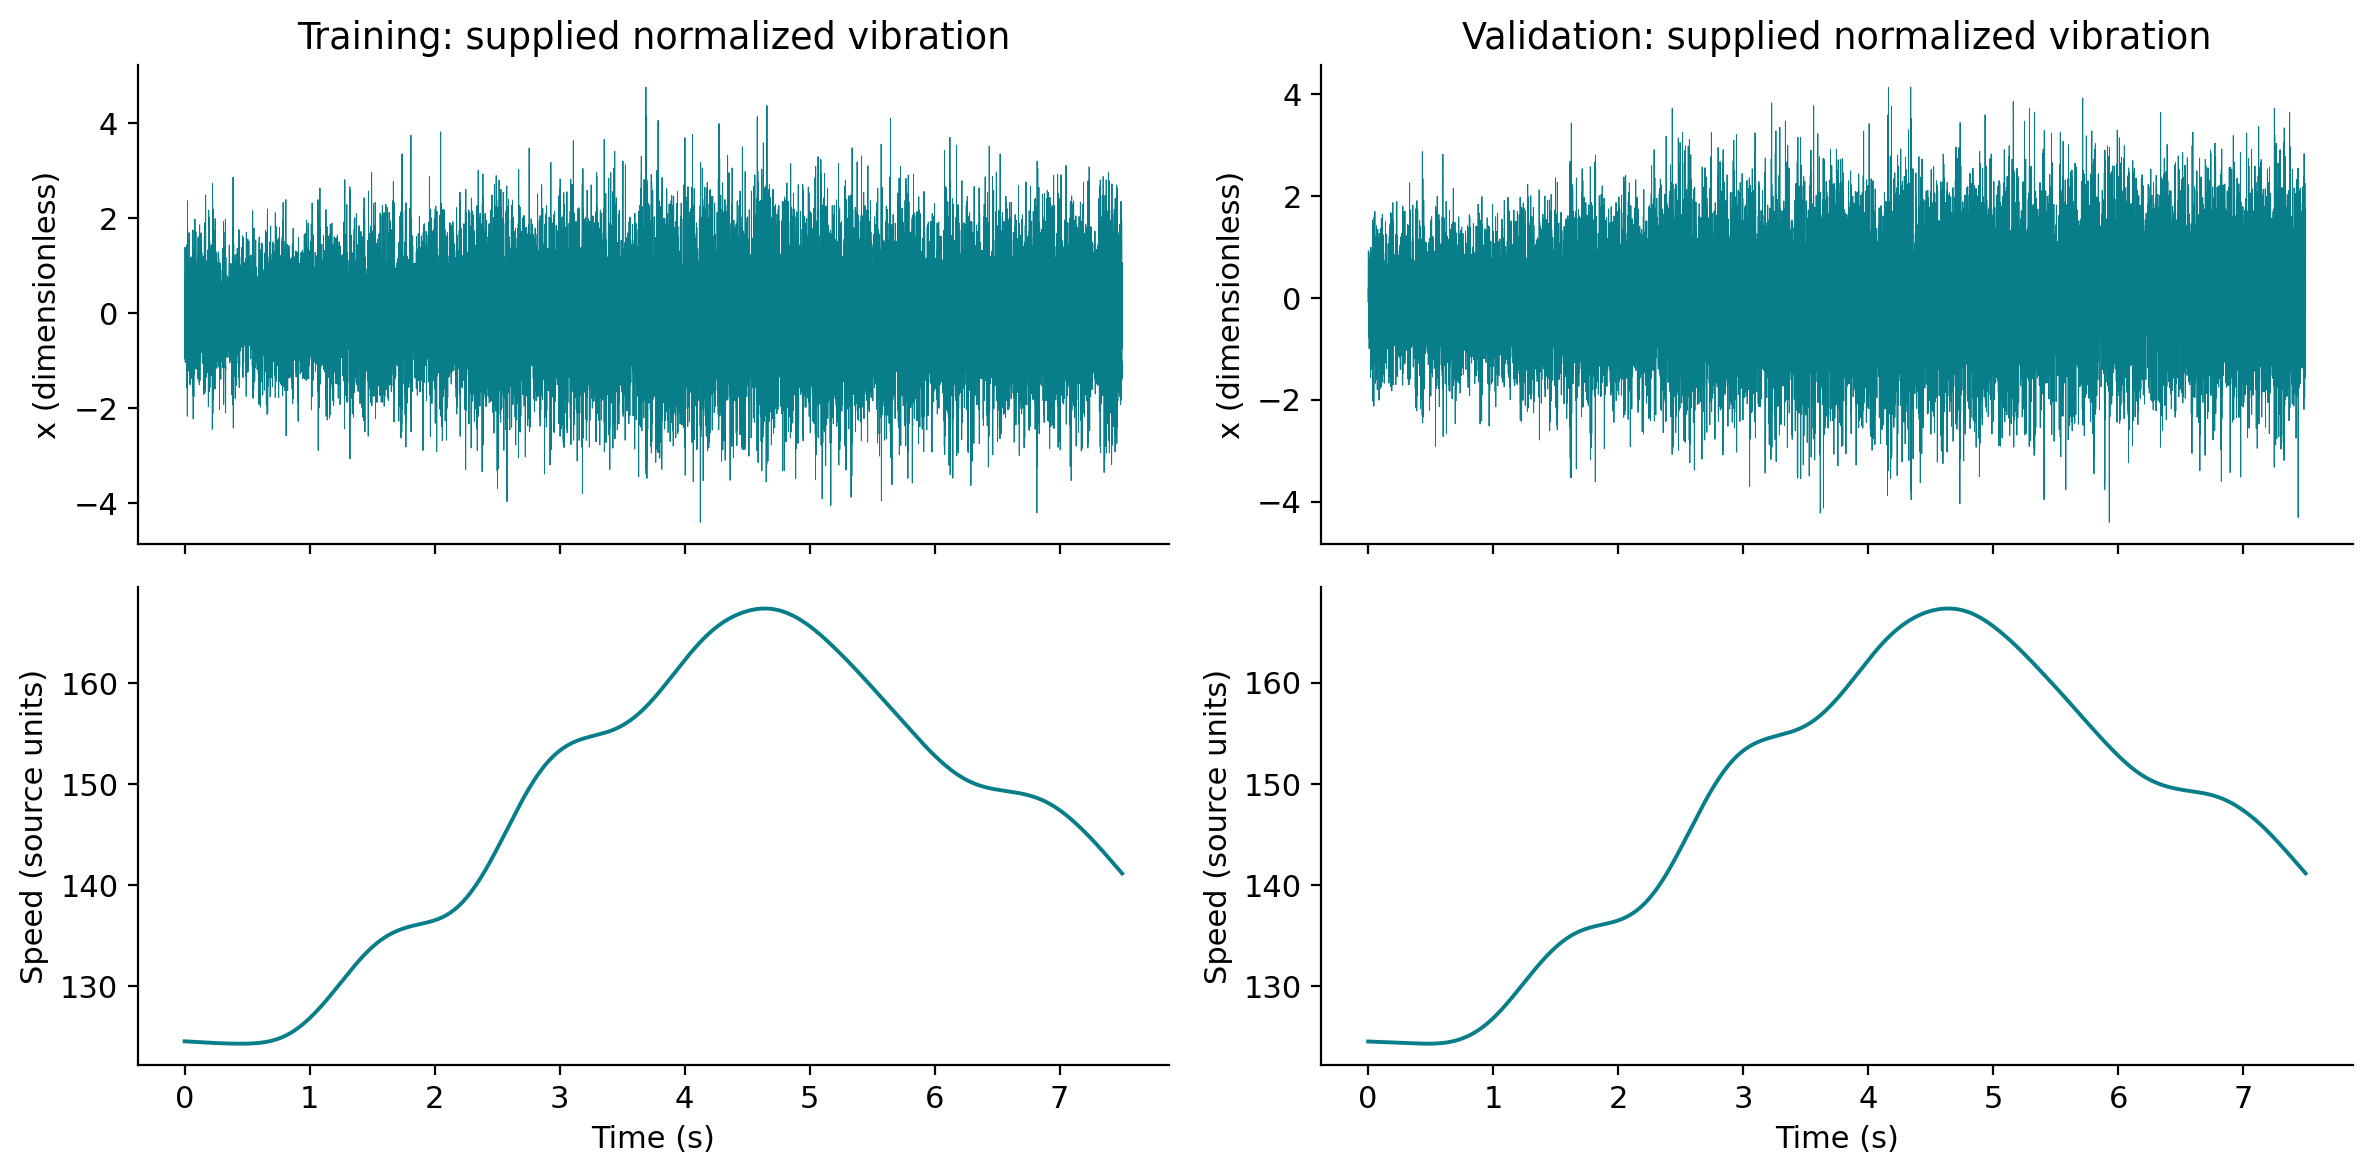

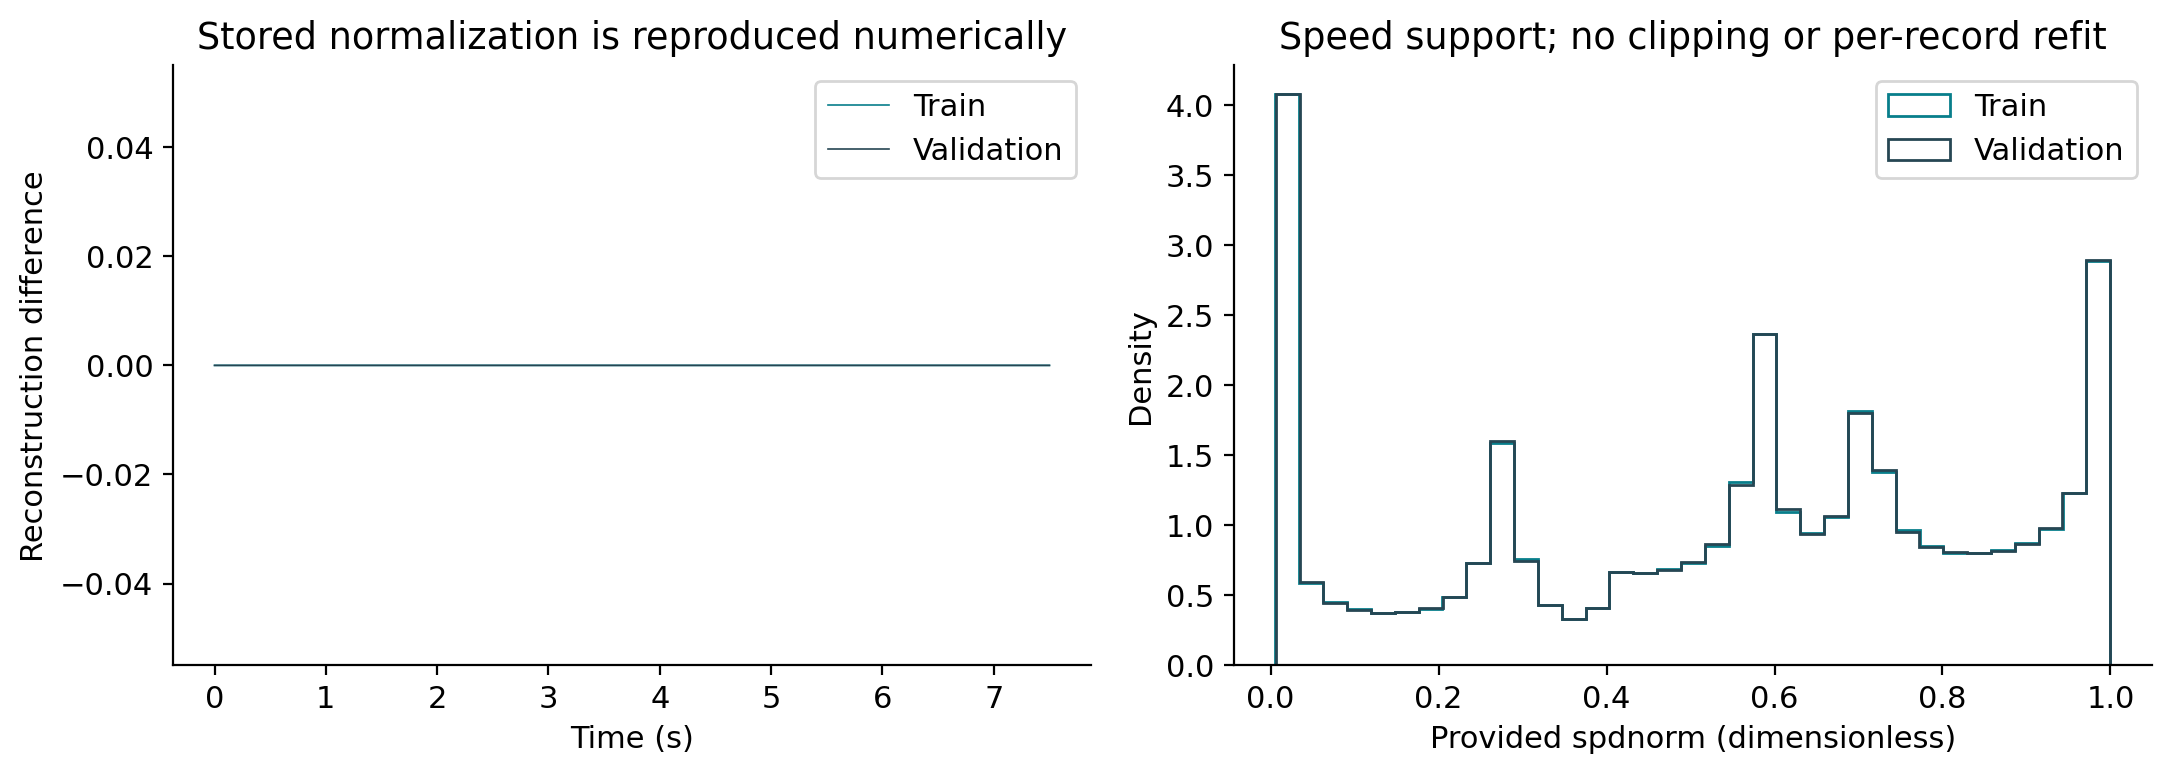

In [5]:
display(pd.Series(audit["comparisons"], name="Measured comparison"))
display(Image(filename=str(ROOT / "reports/figures/eda.png"), width=1000))
display(Image(filename=str(ROOT / "reports/figures/normalization.png"), width=1000))

## 3. Sampling, spectra and variable speed

At \(f_s=3200\) samples/s, the sample interval is \(1/f_s=0.0003125\) s and
Nyquist frequency is 1600 Hz. Frequencies beyond Nyquist can alias into the
observed band; no postprocessing can recover information that was not sampled.
A lag of 256 therefore spans 0.080 s, not 256 seconds.

The Welch PSD averages windowed squared Fourier magnitudes; its amplitude-squared
per-Hz units differ from a one-sided amplitude spectrum. A spectrogram repeats
spectral estimation in local windows, revealing changes that a whole-record
spectrum hides. Both are retrospective EDA and are not predictor input features.

,L_samples,history_ms,available_targets_train
0,32,10.0,23968
1,64,20.0,23936
2,128,40.0,23872
3,256,80.0,23744


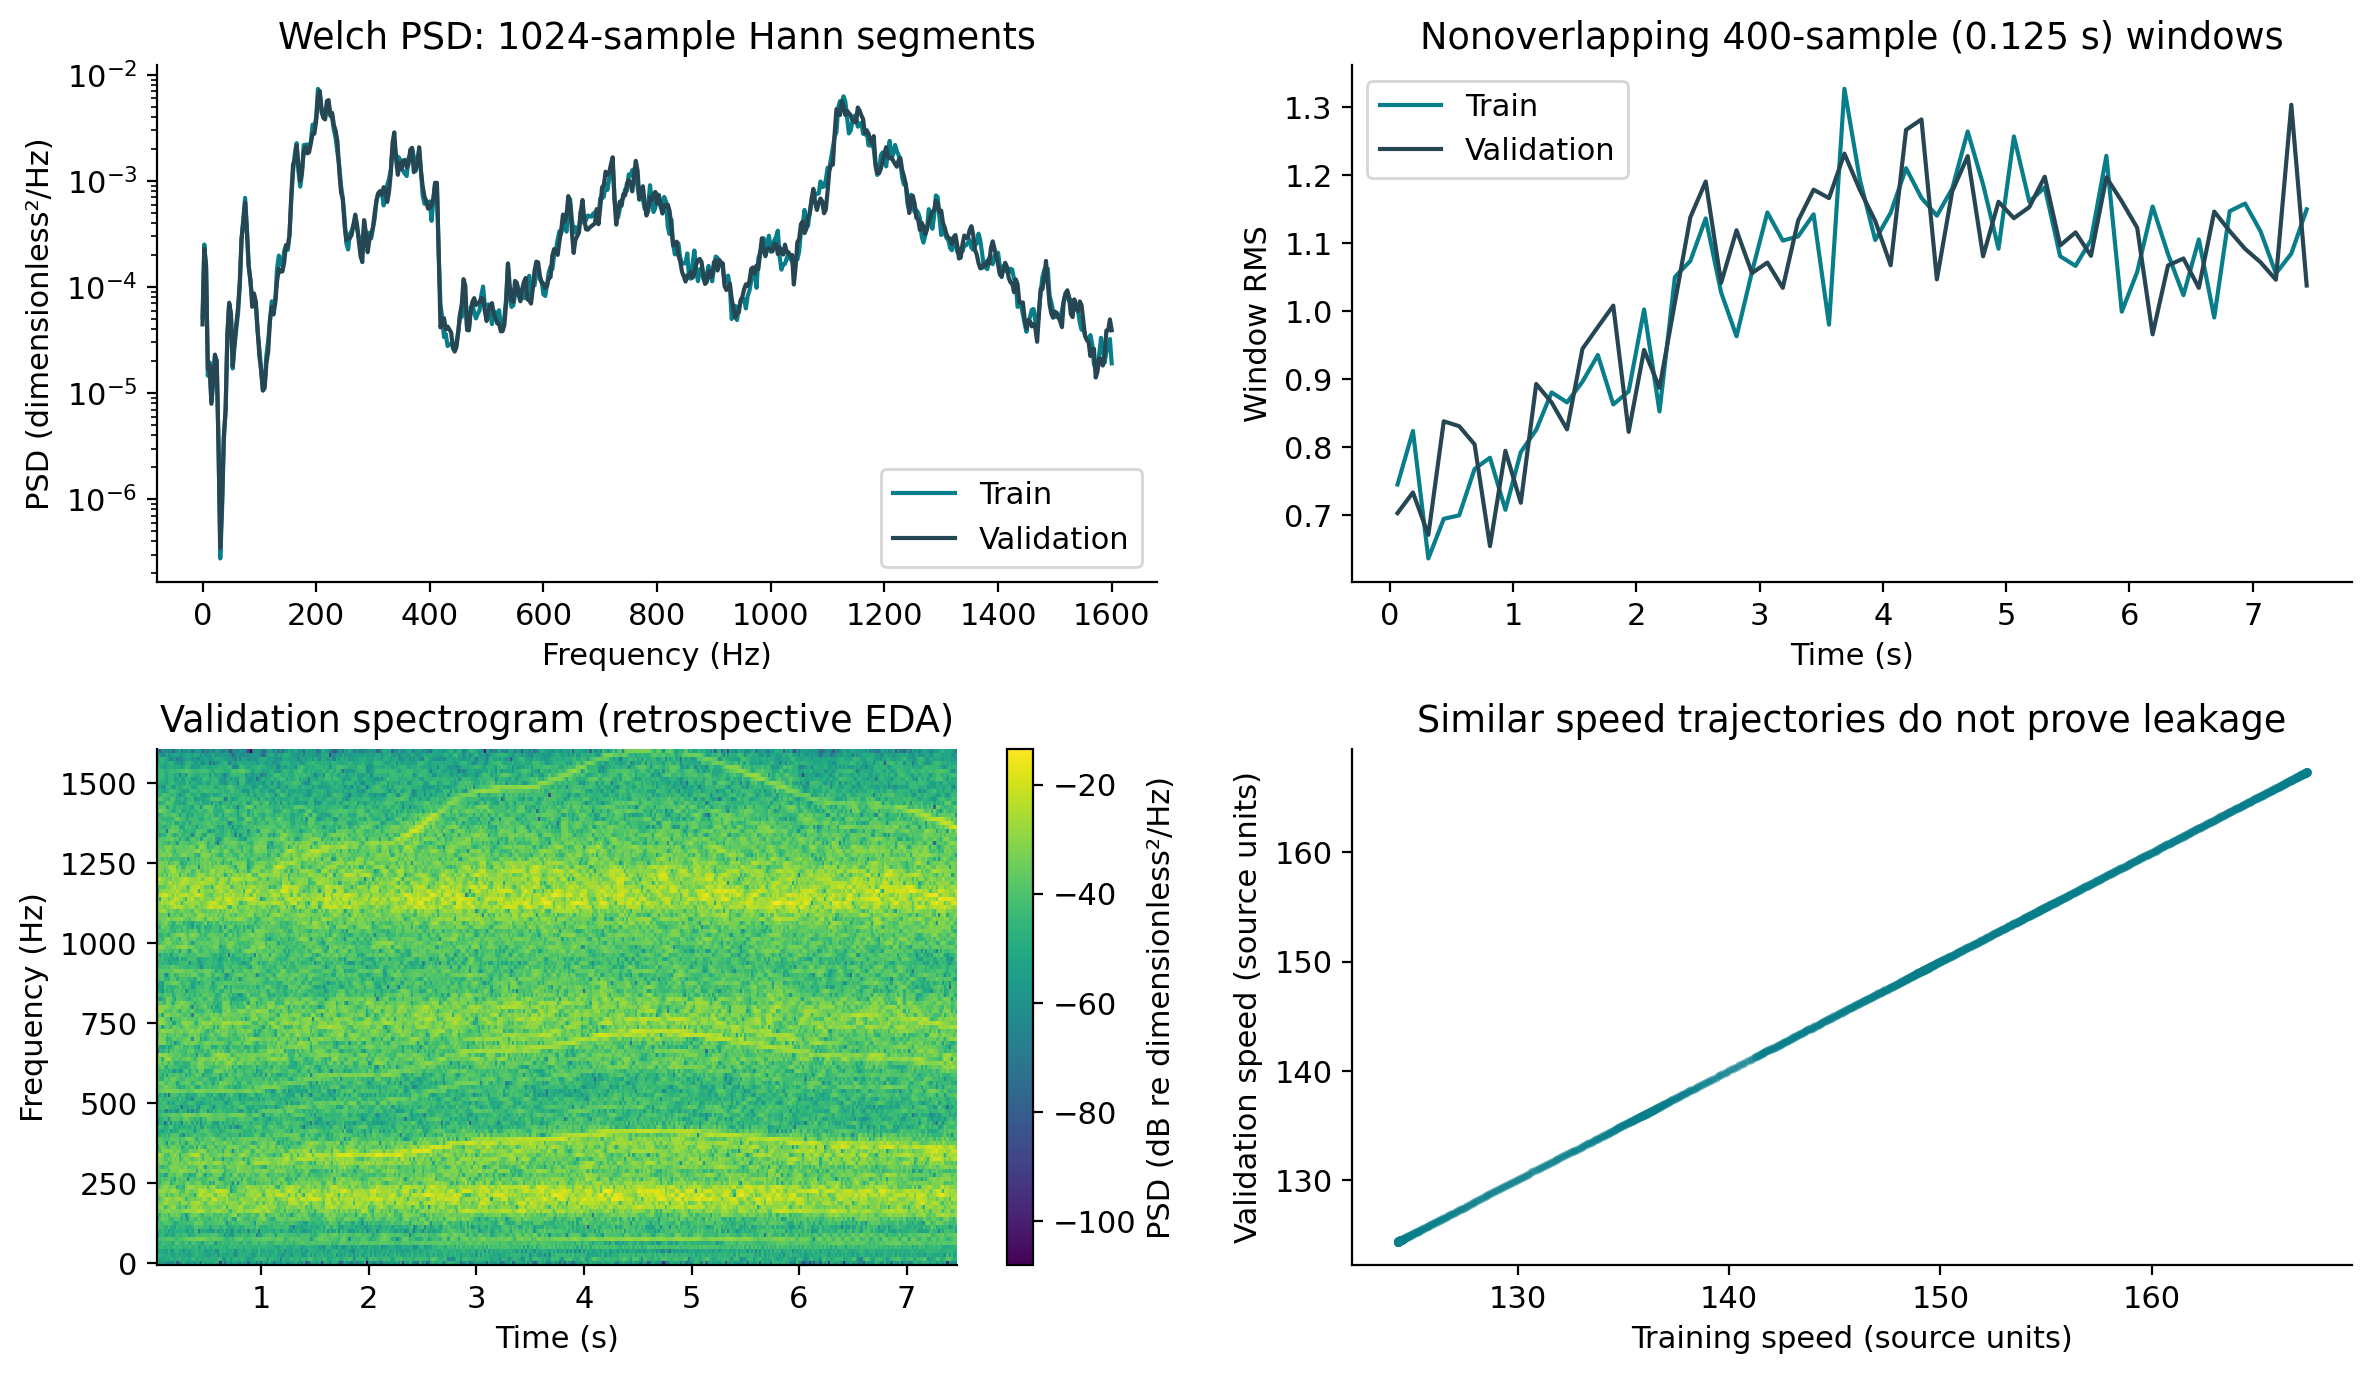

In [6]:
context = pd.DataFrame({"L_samples": [32, 64, 128, 256]})
context["history_ms"] = context.L_samples / train["fs"] * 1000
context["available_targets_train"] = train["N"] - context.L_samples
display(context)
display(Image(filename=str(ROOT / "reports/figures/spectral_eda.png"), width=1000))

Speed variation moves rotation-related frequency components in time. However,
a spectral peak is not sufficient to identify tooth count, shaft order, physical
fault frequency, or the speed unit. Those require independent mechanical metadata.
Constant speed would map a fixed order to a fixed frequency; variable speed makes
that frequency drift. This motivates speed-conditioned prediction and explicit-unit
angular diagnostics, not an unsupported physical interpretation of every peak.

## 4. Strictly causal windows and fair evaluation

The primary task is teacher-forced one-step prediction:
\[
\hat x_t=f(x_{t-L},\ldots,x_{t-1},s_{t-L},\ldots,s_{t-1}).
\]
At each time, previous true samples are observed. This differs from free-running
forecasting, where the model feeds earlier predictions back into itself. No
contemporaneous `x[t]` or future vibration/speed is available to the causal model.

For the toy sequence [10,20,30,40,50] with L=3, the first input is [10,20,30]
and its target is 40. We make that indexing visible before trusting the full dataset.

In [7]:
from rotmach.windows import make_windows
toy = {"x": np.array([10.,20.,30.,40.,50.]), "spdnorm": np.arange(5.)/4}
Xtoy, ytoy, itoy = make_windows(toy, 3)
display(pd.DataFrame({"window": list(Xtoy), "target": ytoy, "target_index": itoy}))
assert np.array_equal(Xtoy[0], [10,20,30]) and ytoy[0] == 40
X, targets, indices = make_windows(train, 64, "tcn")
print("Neural tensor [windows, channels, time]:", X.shape)
assert np.array_equal(X[0,0], train["x"][:64].astype(np.float32))
assert targets[0] == train["x"][64]

,window,target,target_index
0,"[10.0, 20.0, 30.0]",40.0,3
1,"[20.0, 30.0, 40.0]",50.0,4


Neural tensor [windows, channels, time]: (23936, 2, 64)


### The comparison target set is fixed

All reported runs evaluate indices **256 through 23999 inclusive**, giving 23,744
validation targets. A shorter-history model does not gain easier extra samples.
Training and validation come from different supplied recordings. Randomly splitting
overlapping windows from one trace into train and test would overstate independence;
window shuffling within an already defined training trace is merely minibatch order.

Checkpoint selection and method choice use the supplied validation recording.
Consequently these are **validation results**, potentially optimistic after selection,
not a final unbiased test. `sigtest.mat` was not supplied.

In [8]:
results = pd.read_csv(ROOT / "reports/results_summary.csv")
assert (results.start_index == 256).all()
assert (results.end_index == 23999).all()
assert (results.n_targets == 23744).all()
assert set(results.split) == {"validation"}
print("Verified common evaluation targets for", len(results), "completed runs.")

Verified common evaluation targets for 31 completed runs.


## 5. Baselines and fitted checkpoints

A zero predictor gives 0; an empirical-mean predictor gives the training mean;
persistence gives \(x_{t-1}\). These answer different questions and all deserve
measurement. Linear AR fits \(\hat x_t=b+\sum_{j=1}^{L}a_jx_{t-j}\).
Ridge minimizes
\[
\|y-Xa-b\mathbf 1\|_2^2+\alpha\|a\|_2^2,
\]
with the intercept unpenalized. The regularization improves stability when lag
columns are correlated. Scikit-learn's objective is a **sum** of squared errors,
so its alpha cannot be compared blindly to an average-loss implementation.

The causal ARX adds last observed normalized speed and its square. The LPV-AR
surrogate adds speed×lag and speed²×lag interactions. It is neither an innovation
recursion nor an exact reproduction of the cited sparse LPV-ARMA paper.

### Independently fit a real ridge baseline

Loading a model checks packaging; fitting a fresh one checks the regression
construction. The lag matrix uses oldest-to-newest history, an unpenalized
intercept, alpha=1, and the same evaluation targets. This small deterministic
CPU fit stays inexpensive; nonlinear retraining remains an explicit full-run step.

In [9]:
from sklearn.linear_model import Ridge
A, b, train_indices = make_windows(train, 256, "ar")
Av, bv, valid_indices = make_windows(valid, 256, "ar")
ridge = Ridge(alpha=1.0, fit_intercept=True, solver="cholesky").fit(A,b)
fresh_prediction = ridge.predict(Av)
fresh_mse = float(np.mean((bv-fresh_prediction)**2))
reported_ridge = results[(results.kind=="ar") & (results.lag==256)].iloc[0]
assert np.isclose(fresh_mse,reported_ridge.mse,rtol=1e-8,atol=1e-10)
print("PASS: freshly fitted ridge agrees with official MSE:",fresh_mse)

PASS: freshly fitted ridge agrees with official MSE: 0.42005759033115847


In [10]:
baselines = results[results.kind.isin(["zero","mean","persistence","ols","ar","arx","lpv"])]
display(baselines[["run_id","lag","mse","parameters","train_wall_s",
                   "inference_record_median_s"]].sort_values("mse").reset_index(drop=True))

,run_id,lag,mse,parameters,train_wall_s,inference_record_median_s
0,lpv_L256_s17_a1,256,0.361217,769,0.765804,0.122543
1,lpv_L128_s17_a1,128,0.381163,385,0.450643,0.031192
2,lpv_L64_s17_a1,64,0.394738,193,0.047654,0.012896
3,ar_L256_s17_a1,256,0.420058,257,0.069029,0.006647
4,ols_L256_s17,256,0.420059,257,0.263791,0.006362
5,ar_L128_s17_a1,128,0.426825,129,0.027784,0.003237
6,arx_L256_s17_a1,256,0.427821,259,0.063736,0.007752
7,arx_L128_s17_a1,128,0.430216,131,0.026958,0.004128
8,ar_L64_s17_a1,64,0.439050,65,0.012017,0.001776
9,arx_L64_s17_a1,64,0.443191,67,0.014981,0.002280


### A model artifact must actually reload

The package exposes one public prediction path returning a full-length array;
NaNs mark unavailable initial history. We verify its recomputed MSE and saved
predictions rather than assuming a file's presence means a usable trained model.
Only load pickle model files created locally or from a trusted project release.

In [11]:
from rotmach.experiment import load_model_and_predict, metrics
best = json.loads((ROOT / "experiments/best_model.json").read_text())
best_id = best["run_id"]
yhat = load_model_and_predict(ROOT, best_id, valid)
common = np.arange(256, valid["N"])
measured = metrics(valid["x"][common], yhat[common])
assert np.isclose(measured["mse"], best["mse"], rtol=1e-6, atol=1e-8)
saved = np.load(ROOT / "experiments/runs" / best_id / "predictions.npz")
assert np.allclose(saved["y_pred"], yhat[common], rtol=1e-5, atol=1e-6)
print("Reloaded best run:", best_id)
display(pd.Series(measured, name="Recomputed validation metrics"))

Reloaded best run: lpv_L256_s17_a1


mse     0.361217
rmse    0.601014
mae     0.475400
nmse    0.327167
Name: Recomputed validation metrics, dtype: float64

### Challenge causality by changing the future

A causal earlier prediction must survive a future-data perturbation. We change
vibration and speed from index 5000 onward; predictions before index 5000 must
remain unchanged. This tests the selected causal predictor. The intentionally
shifted-speed offline control is excluded from the causal recommendation.

In [12]:
import copy
perturbed = copy.deepcopy(valid)
perturbed["x"][5000:] += 10
perturbed["spdnorm"][5000:] -= 3
altered_yhat = load_model_and_predict(ROOT,best_id,perturbed)
assert np.allclose(yhat[256:5000],altered_yhat[256:5000],atol=1e-6,rtol=1e-5)
print("PASS: future perturbations preserve earlier causal predictions.")

PASS: future perturbations preserve earlier causal predictions.


## 6. Compact advanced models

**MLP:** a fixed lag vector passes through a hidden nonlinear layer. It checks
whether a nonlinear function helps without attributing every improvement to a
sequence architecture.

**GRU:** a unidirectional recurrent model updates a hidden state while reading
only the past window. Reset and update gates regulate which information remains:
\(r=\sigma(W_rx+U_rh)\), \(z=\sigma(W_zx+U_zh)\), followed by a candidate
state and a gate-weighted combination. Framework GRU details determine exactly
where the reset gate multiplies the recurrent affine term; use the implemented
PyTorch convention rather than assuming all textbook expressions are identical.
The hidden state is reset per window in this experiment, not carried across
recording boundaries.

**TCN:** left padding makes convolutions causal. Dilations 1,2,4,… broaden
history without a long recurrent loop. Each residual block here has two kernel-3
convolutions; receptive field is \(R=1+4\sum_i d_i\). Input windows cap the
available real history even when theoretical R exceeds L.

In [13]:
from rotmach.models import build_network
architecture_rows=[]
for kind in ["mlp","gru","tcn","speed_tcn","late_tcn","capacity_tcn"]:
    channels=9 if kind=="capacity_tcn" else 8
    net=build_network(kind,64,channels)
    with torch.no_grad(): out=net(torch.from_numpy(X[:4]))
    assert tuple(out.shape)==(4,)
    architecture_rows.append(dict(kind=kind,parameters=sum(p.numel() for p in net.parameters()),
                                  receptive_field=getattr(net,"receptive_field",None)))
display(pd.DataFrame(architecture_rows))

,kind,parameters,receptive_field
0,mlp,2113,NaN
1,gru,929,NaN
2,tcn,2025,125.0
3,speed_tcn,2185,125.0
4,late_tcn,2026,125.0
5,capacity_tcn,2548,125.0


### Speed conditioning is a falsifiable project contribution

The FiLM-style TCN uses observed past speed to modulate channel activations:
\(h'=h[1+0.1\tanh\gamma(s)]+0.1\beta(s)\). The fixed 0.1 factors limit
initial conditioning amplitude; they do not guarantee speed will improve MSE.
The same convolutional core is compared with an unconditioned TCN, a late-speed
concatenation variant, and a larger unconditioned channel-count control.

A phase-shifted-speed **negative control** is explicitly an offline intervention.
It may violate the natural online speed-availability assumption and is excluded
from causal winner selection. It is a sensitivity probe, not a deployment method.
FiLM is established literature; the novelty is an adaptation and controlled
comparison in this project, not a claim of a world-first architecture.

In [14]:
neural = results[~results.kind.isin(["zero","mean","persistence","ols","ar","arx","lpv"])]
display(neural[["run_id","kind","causal_status","lag","seed","mse","parameters","epochs_completed",
                "train_wall_s"]].sort_values(["kind","lag","seed"]))
example_id = neural[neural.kind=="speed_tcn"].iloc[0].run_id
config = json.loads((ROOT / "experiments/runs" / example_id / "config.json").read_text())
display(pd.Series({k: config[k] for k in ["kind","lag","channels","learning_rate",
        "weight_decay","batch_size","epochs","patience","seed","burnin"]}))

,run_id,kind,causal_status,lag,seed,mse,parameters,epochs_completed,train_wall_s
19,capacity_tcn_L64_s17,capacity_tcn,past-only causal,64,17,0.471419,2548,10,21.795842
27,gru_L64_s17,gru,past-only causal,64,17,0.823606,929,10,12.339703
16,late_tcn_L64_s17,late_tcn,past-only causal,64,17,0.463274,2026,10,19.411123
10,mlp_L64_s17,mlp,past-only causal,64,17,0.450469,2113,8,1.489657
17,shift_tcn_L64_s17,shift_tcn,NONCAUSAL offline speed control,64,17,0.463683,2185,10,25.978204
25,speed_tcn_L32_s17,speed_tcn,past-only causal,32,17,0.512236,1753,10,10.519432
20,speed_tcn_L64_s17,speed_tcn,past-only causal,64,17,0.483214,2185,9,20.098585
22,speed_tcn_L64_s29,speed_tcn,past-only causal,64,29,0.494911,2185,8,17.724904
14,speed_tcn_L64_s43,speed_tcn,past-only causal,64,43,0.459519,2185,10,22.363303
13,speed_tcn_L128_s17,speed_tcn,past-only causal,128,17,0.458226,2617,10,52.985214


kind             speed_tcn
lag                    128
channels                 8
learning_rate        0.003
weight_decay        0.0001
batch_size             512
epochs                  10
patience                 3
seed                    17
burnin                 256
dtype: object

Training uses MSE, AdamW, deterministic seeds, gradient clipping and bounded
epoch counts. The best validation checkpoint is retained with patience-based
stopping. Training-loss decrease alone does not establish useful generalization;
the validation curve may flatten or worsen. Three seeds for the main TCN pair
measure initialization variability on the same validation trace, not variation
between independent machines.

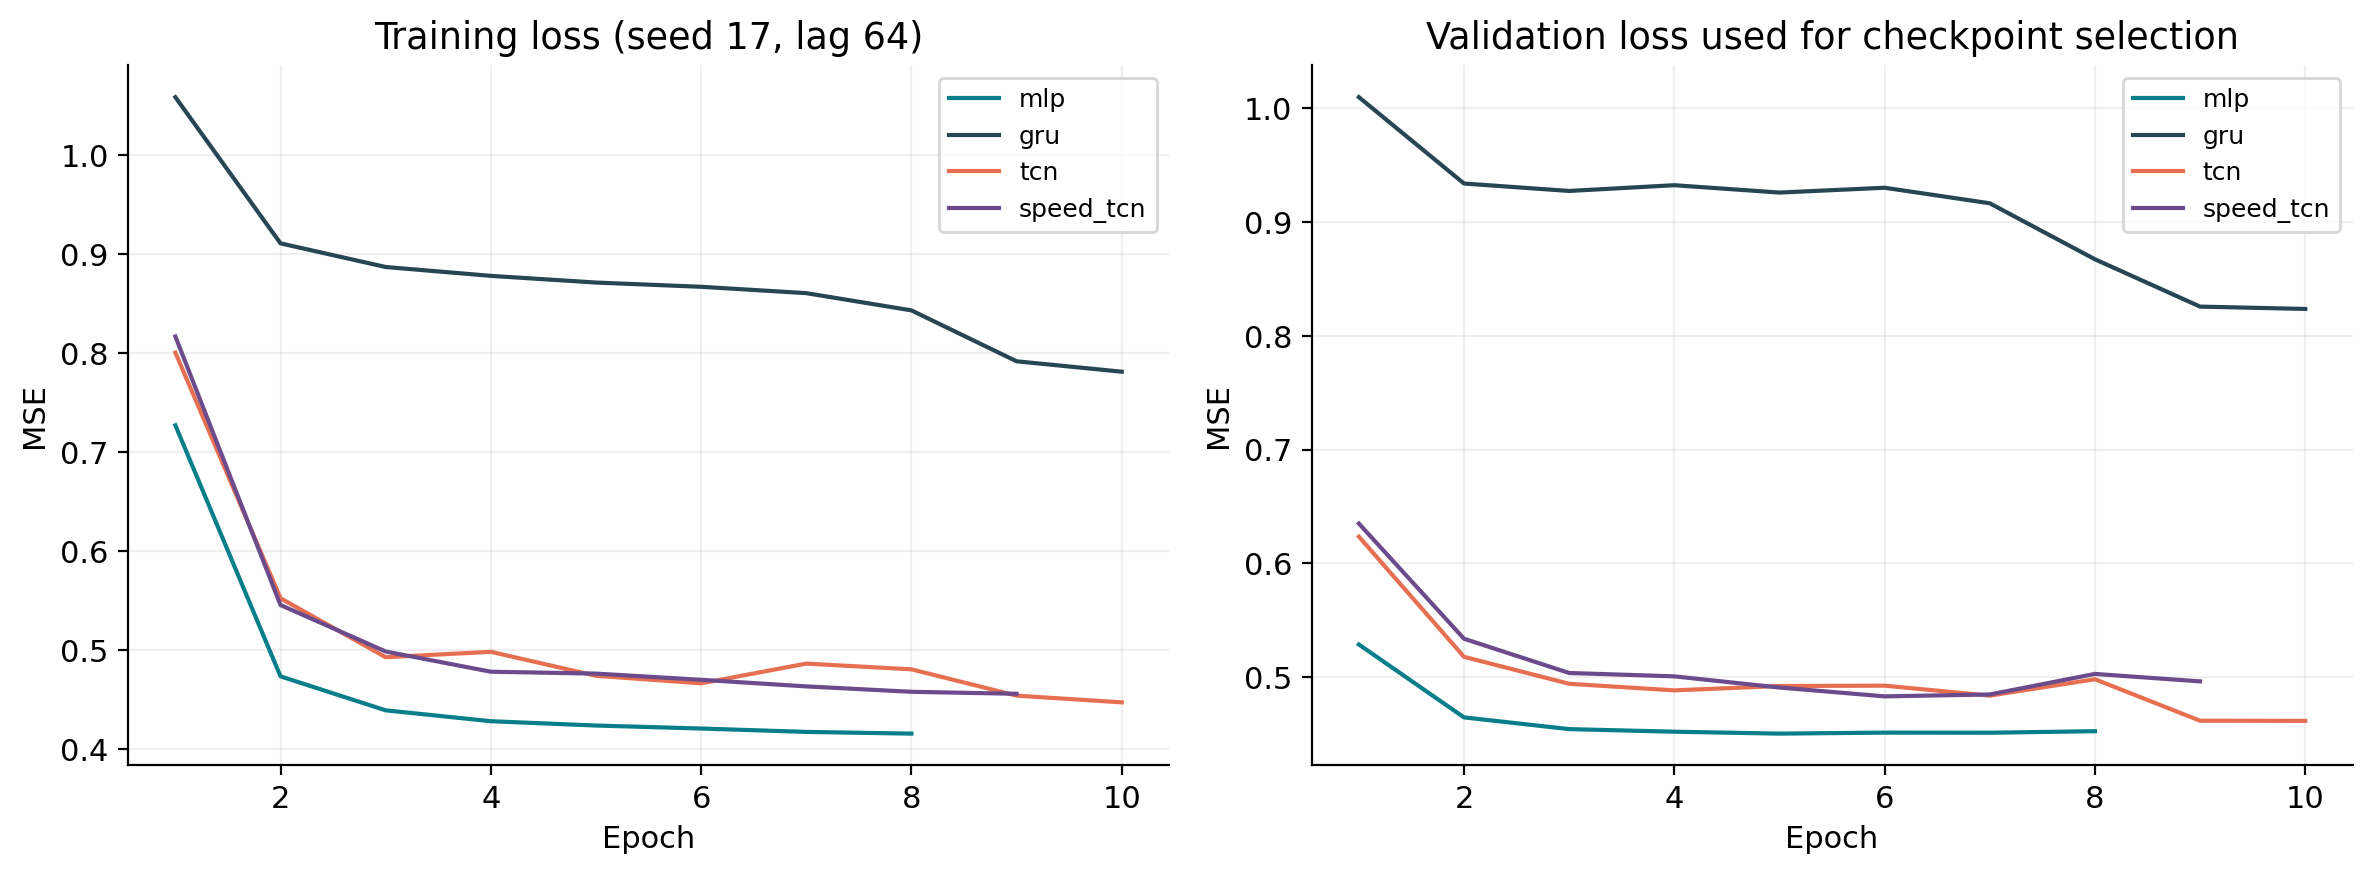

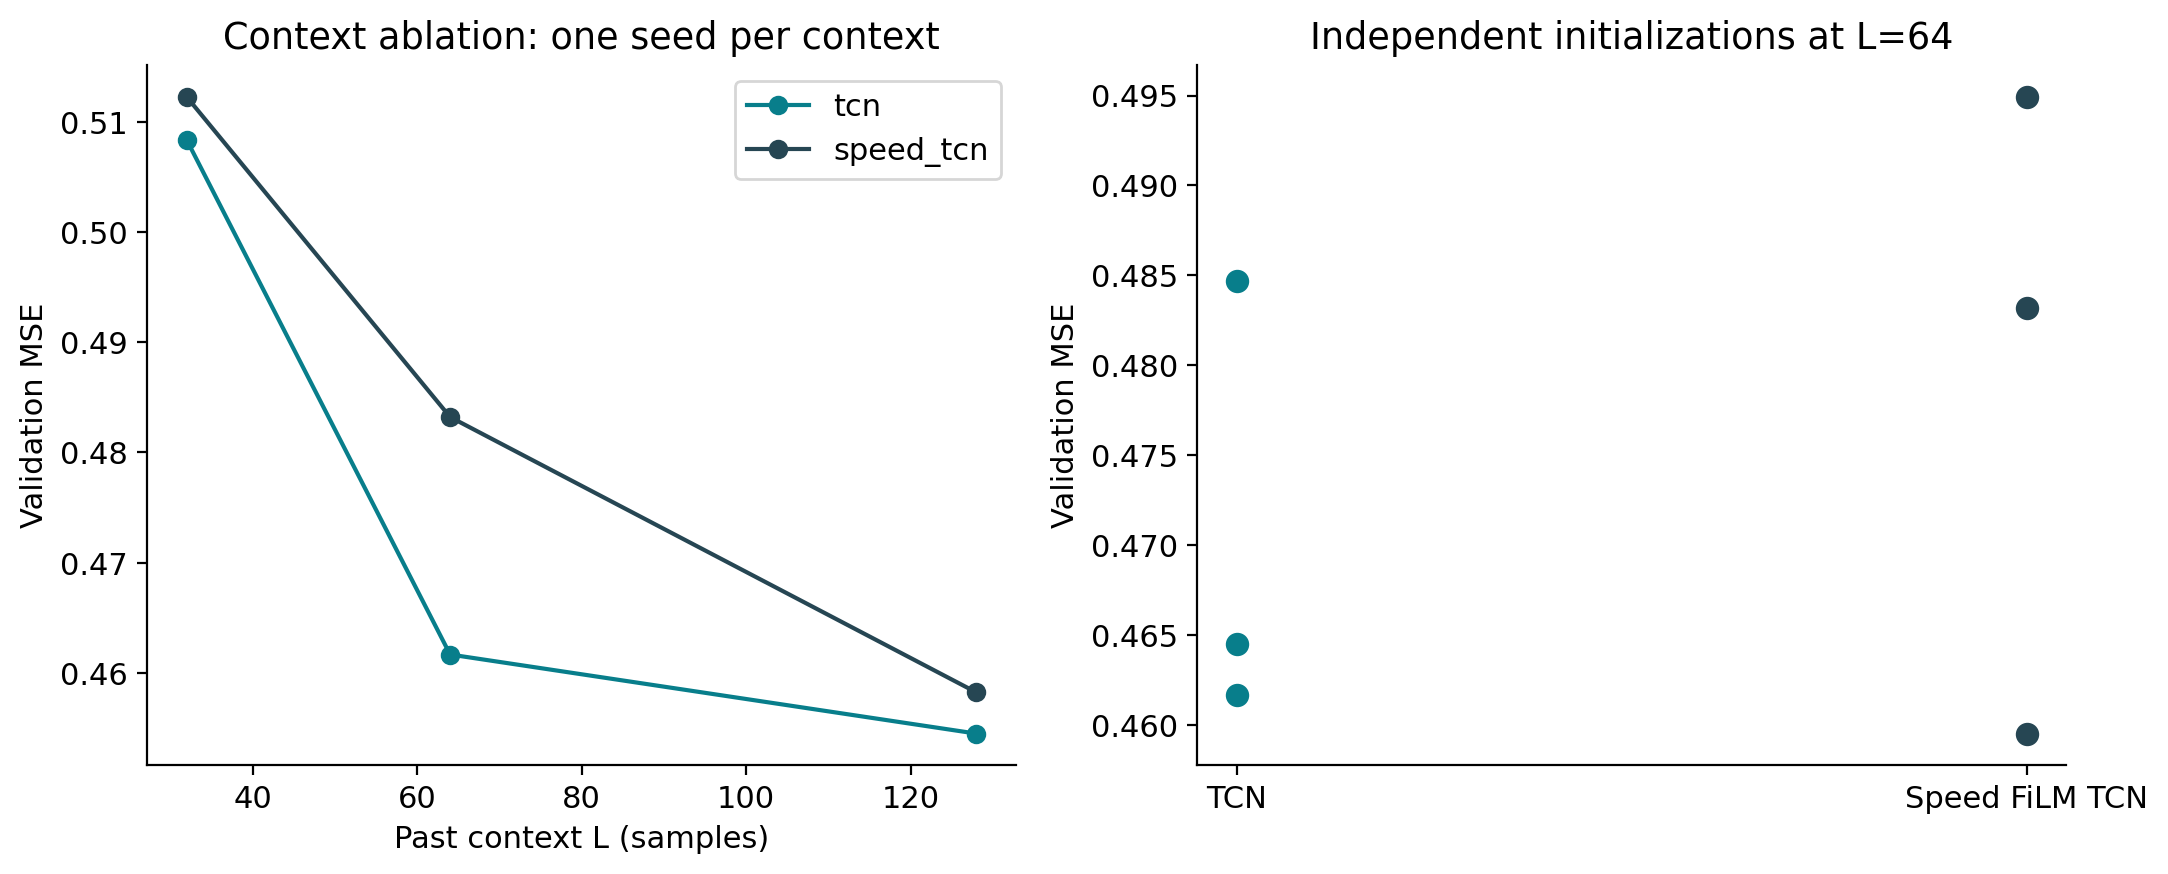

In [15]:
display(Image(filename=str(ROOT / "reports/figures/training_curves.png"), width=1000))
display(Image(filename=str(ROOT / "reports/figures/ablations.png"), width=1000))

## 7. Common-index validation accuracy and CPU cost

MSE is the average squared one-step error. RMSE returns to the amplitude scale;
MAE gives less weight to extreme errors. NMSE here divides MSE by the mean square
of the target; this is distinct from variance-normalized error when the mean is
nonzero. An apparent best run is selected on validation and remains provisional.
Every chart below derives from saved run metrics, not manually entered values.

,run_id,mse,rmse,mae,nmse,parameters,train_wall_s,inference_record_median_s
0,lpv_L256_s17_a1,0.361217,0.601014,0.475400,0.327167,769,0.765804,0.122543
1,lpv_L128_s17_a1,0.381163,0.617384,0.488553,0.345232,385,0.450643,0.031192
2,lpv_L64_s17_a1,0.394738,0.628282,0.496621,0.357528,193,0.047654,0.012896
3,ar_L256_s17_a1,0.420058,0.648119,0.512273,0.380460,257,0.069029,0.006647
4,ols_L256_s17,0.420059,0.648119,0.512274,0.380461,257,0.263791,0.006362
5,ar_L128_s17_a1,0.426825,0.653318,0.516680,0.386590,129,0.027784,0.003237
6,arx_L256_s17_a1,0.427821,0.654081,0.517521,0.387492,259,0.063736,0.007752
7,arx_L128_s17_a1,0.430216,0.655908,0.518987,0.389661,131,0.026958,0.004128
8,ar_L64_s17_a1,0.439050,0.662609,0.524197,0.397663,65,0.012017,0.001776
9,arx_L64_s17_a1,0.443191,0.665726,0.526950,0.401413,67,0.014981,0.002280


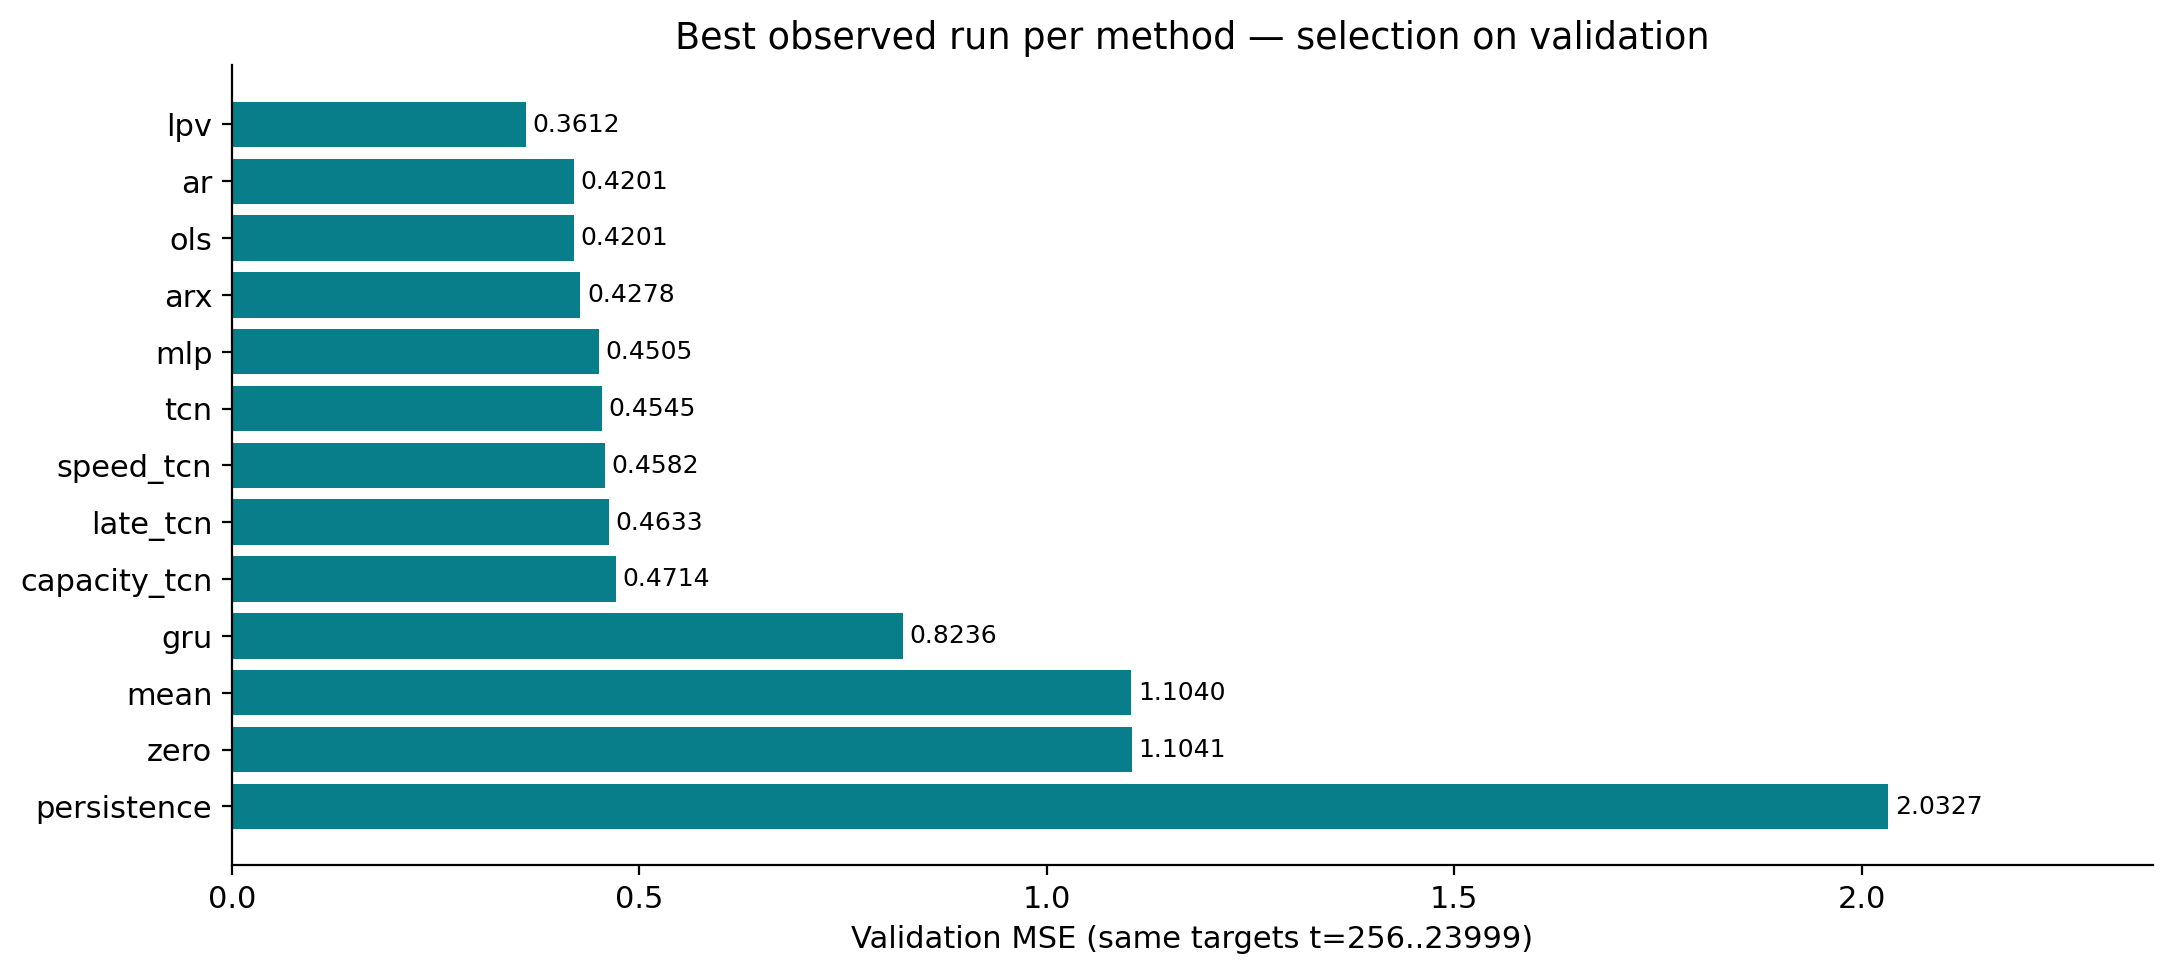

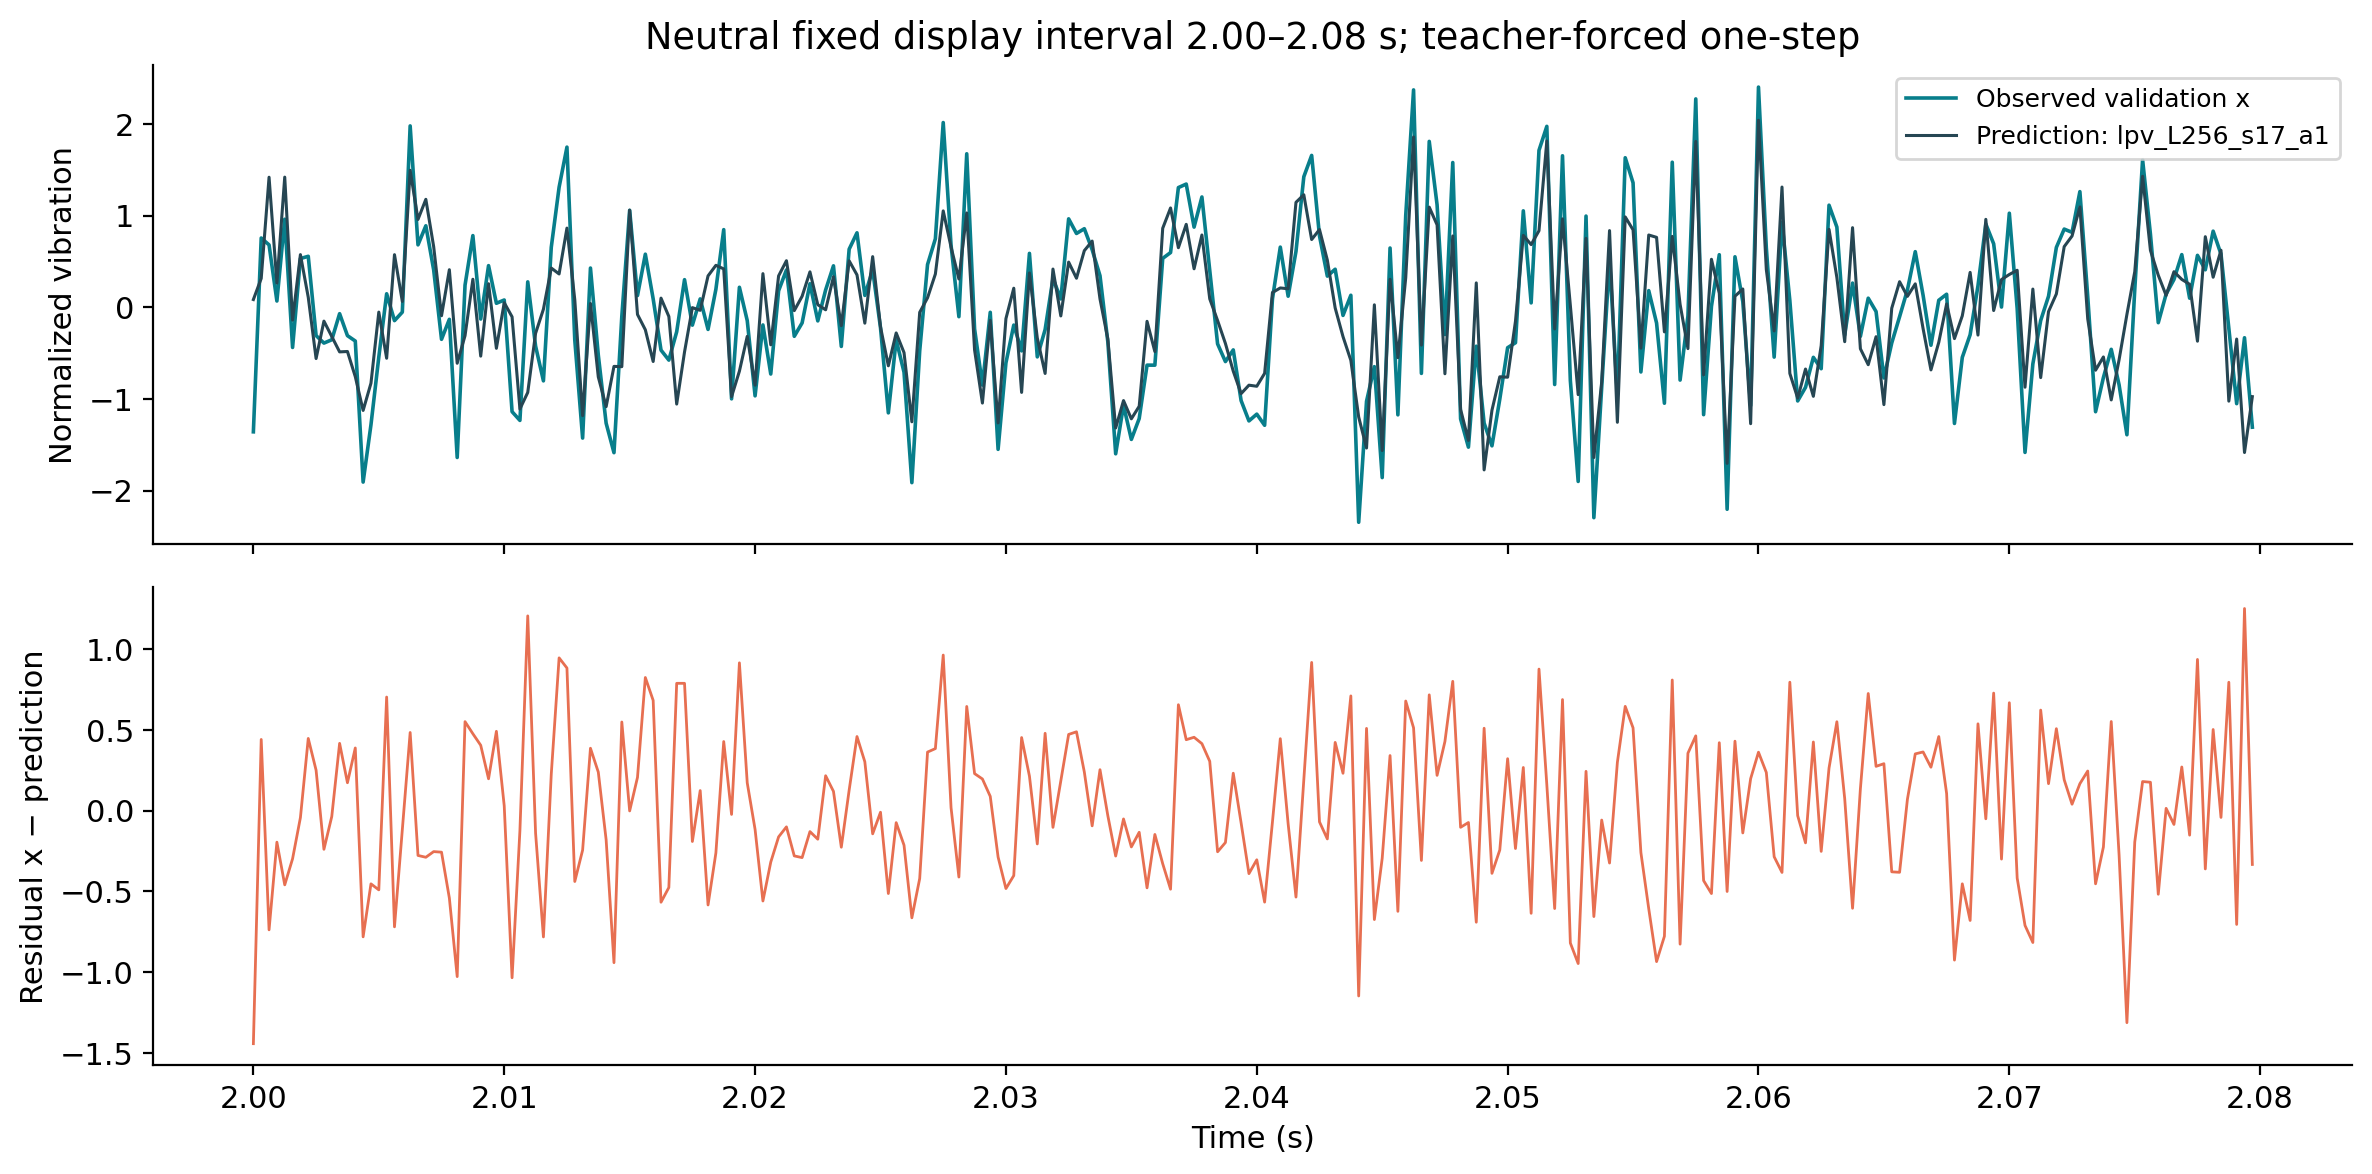

In [16]:
display(results[["run_id","mse","rmse","mae","nmse","parameters",
                 "train_wall_s","inference_record_median_s"]].head(15))
display(Image(filename=str(ROOT / "reports/figures/model_comparison.png"), width=1000))
display(Image(filename=str(ROOT / "reports/figures/prediction.png"), width=1000))

### Timing definitions determine whether a comparison is fair

The saved inference statistic times the **public full-record inference path**:
checkpoint loading, window construction and prediction; one warmup and three
measured repeats, reported by their median and spread. It is not single-sample
streaming latency, kernel-only execution time, or a GPU measurement. Neural
inference uses float32 CPU arrays and bounded batches; linear models use float64.
The recorded training wall timer also includes checkpoint creation and training-loop
validation work. Artifact size and parameter count are useful complexity proxies,
not directly measured peak memory or exact operation counts.

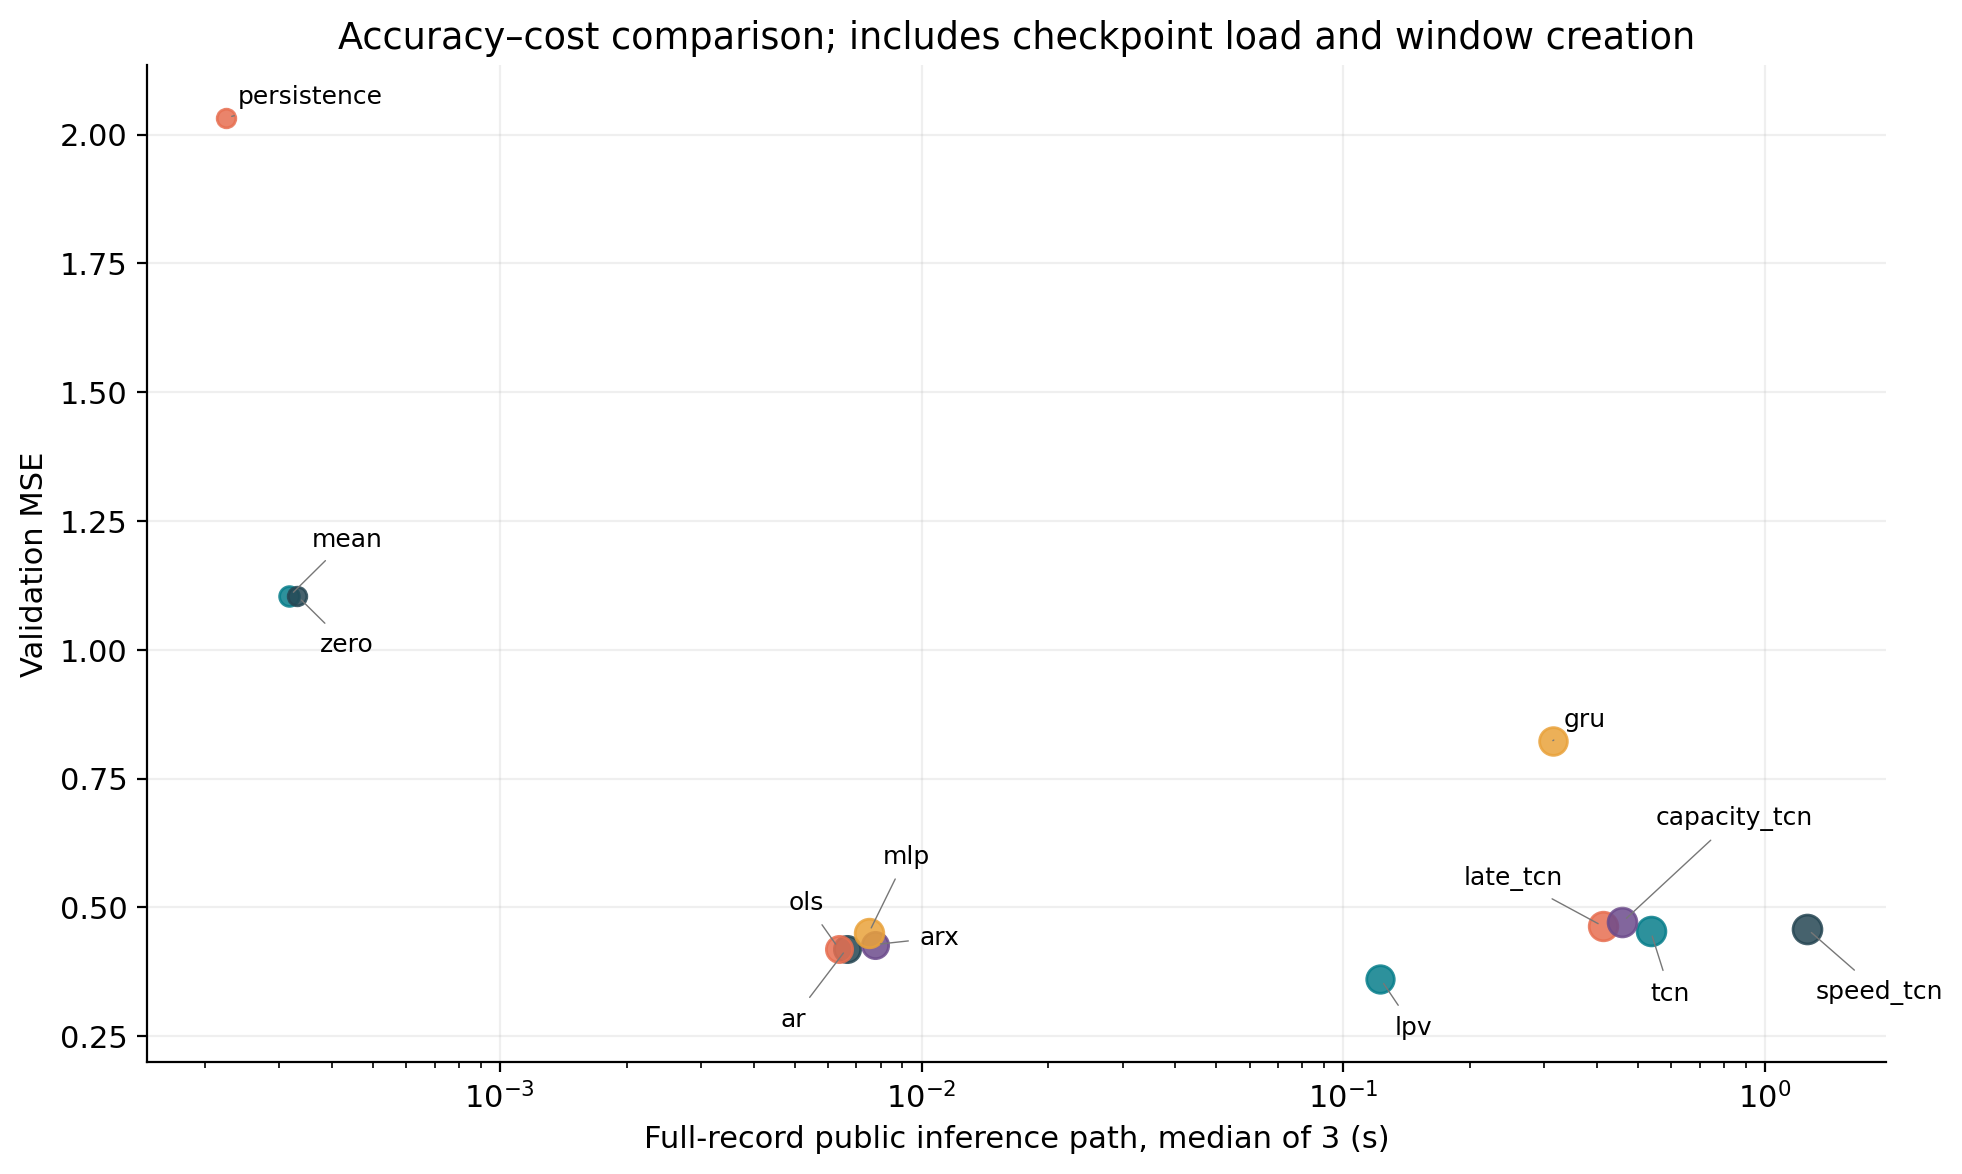

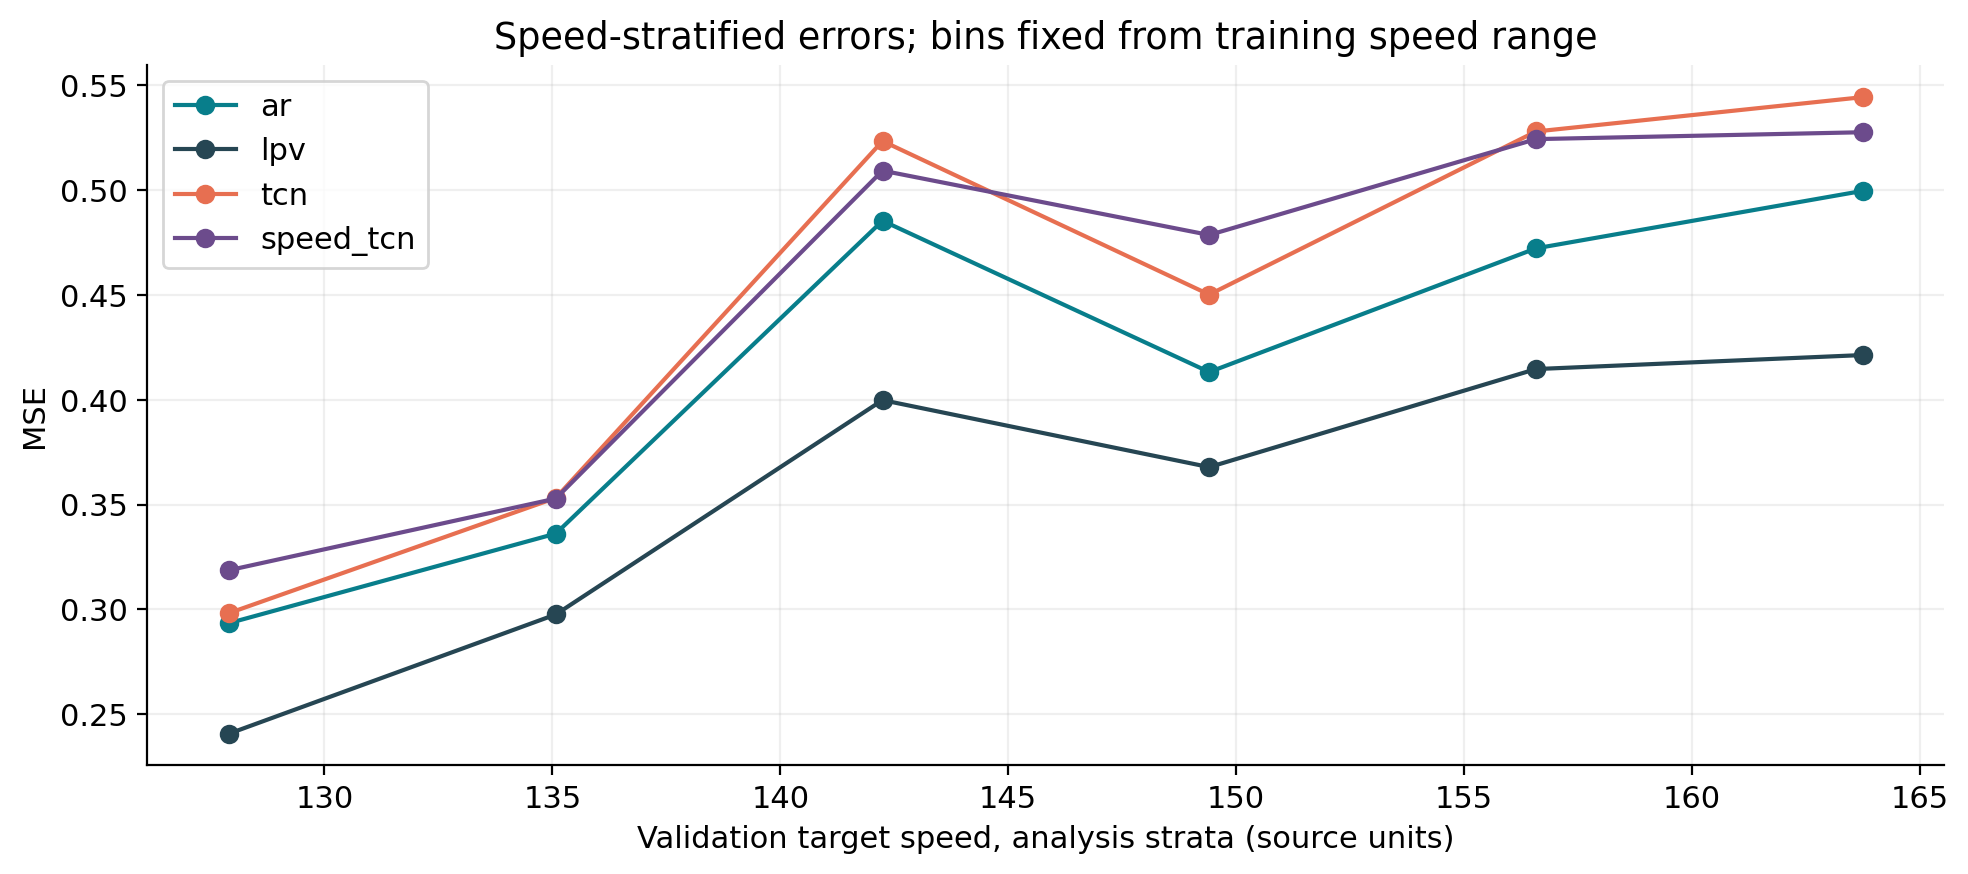

Sum of recorded run training wall times (s): 276.4010805279995
All timings above are measured on this CPU instance; Windows/macOS have not been executed here.


In [17]:
display(Image(filename=str(ROOT / "reports/figures/efficiency.png"), width=1000))
display(Image(filename=str(ROOT / "reports/figures/speed_errors.png"), width=1000))
print("Sum of recorded run training wall times (s):", float(results.train_wall_s.sum()))
print("All timings above are measured on this CPU instance; Windows/macOS have not been executed here.")

The speed plot stratifies validation targets by their observed speed for
**analysis**. This does not imply the causal model saw target-time speed: its
features remain past-only. Bins are fixed from the training range and counts
matter—large uncertainty may occur where few samples lie in a bin.

## 8. Prediction residuals, diagnostics and uncertainty

A residual is \(e_t=x_t-\hat x_t\). Low MSE means low average squared residual
on this trace, not that a fault is easier to identify. An expressive predictor can
also remove repeatable defect content. Residual statistics therefore need their
own comparison and, ultimately, validated physical labels.

RMS is \(\sqrt{N^{-1}\sum e_t^2}\), crest factor is \(\max|e|/RMS\), and
ordinary Pearson kurtosis is the standardized fourth central moment. Its Gaussian
reference is 3, whereas **excess** kurtosis subtracts 3. The implementation uses
biased ordinary kurtosis (`fisher=False, bias=True`); undefined constant-signal
statistics remain NaN, not an invented reassuring zero.

,rms,crest_factor,kurtosis
validation supplied x,1.050751,4.192664,3.188254
validation best-model residual,0.601014,4.012884,3.143244


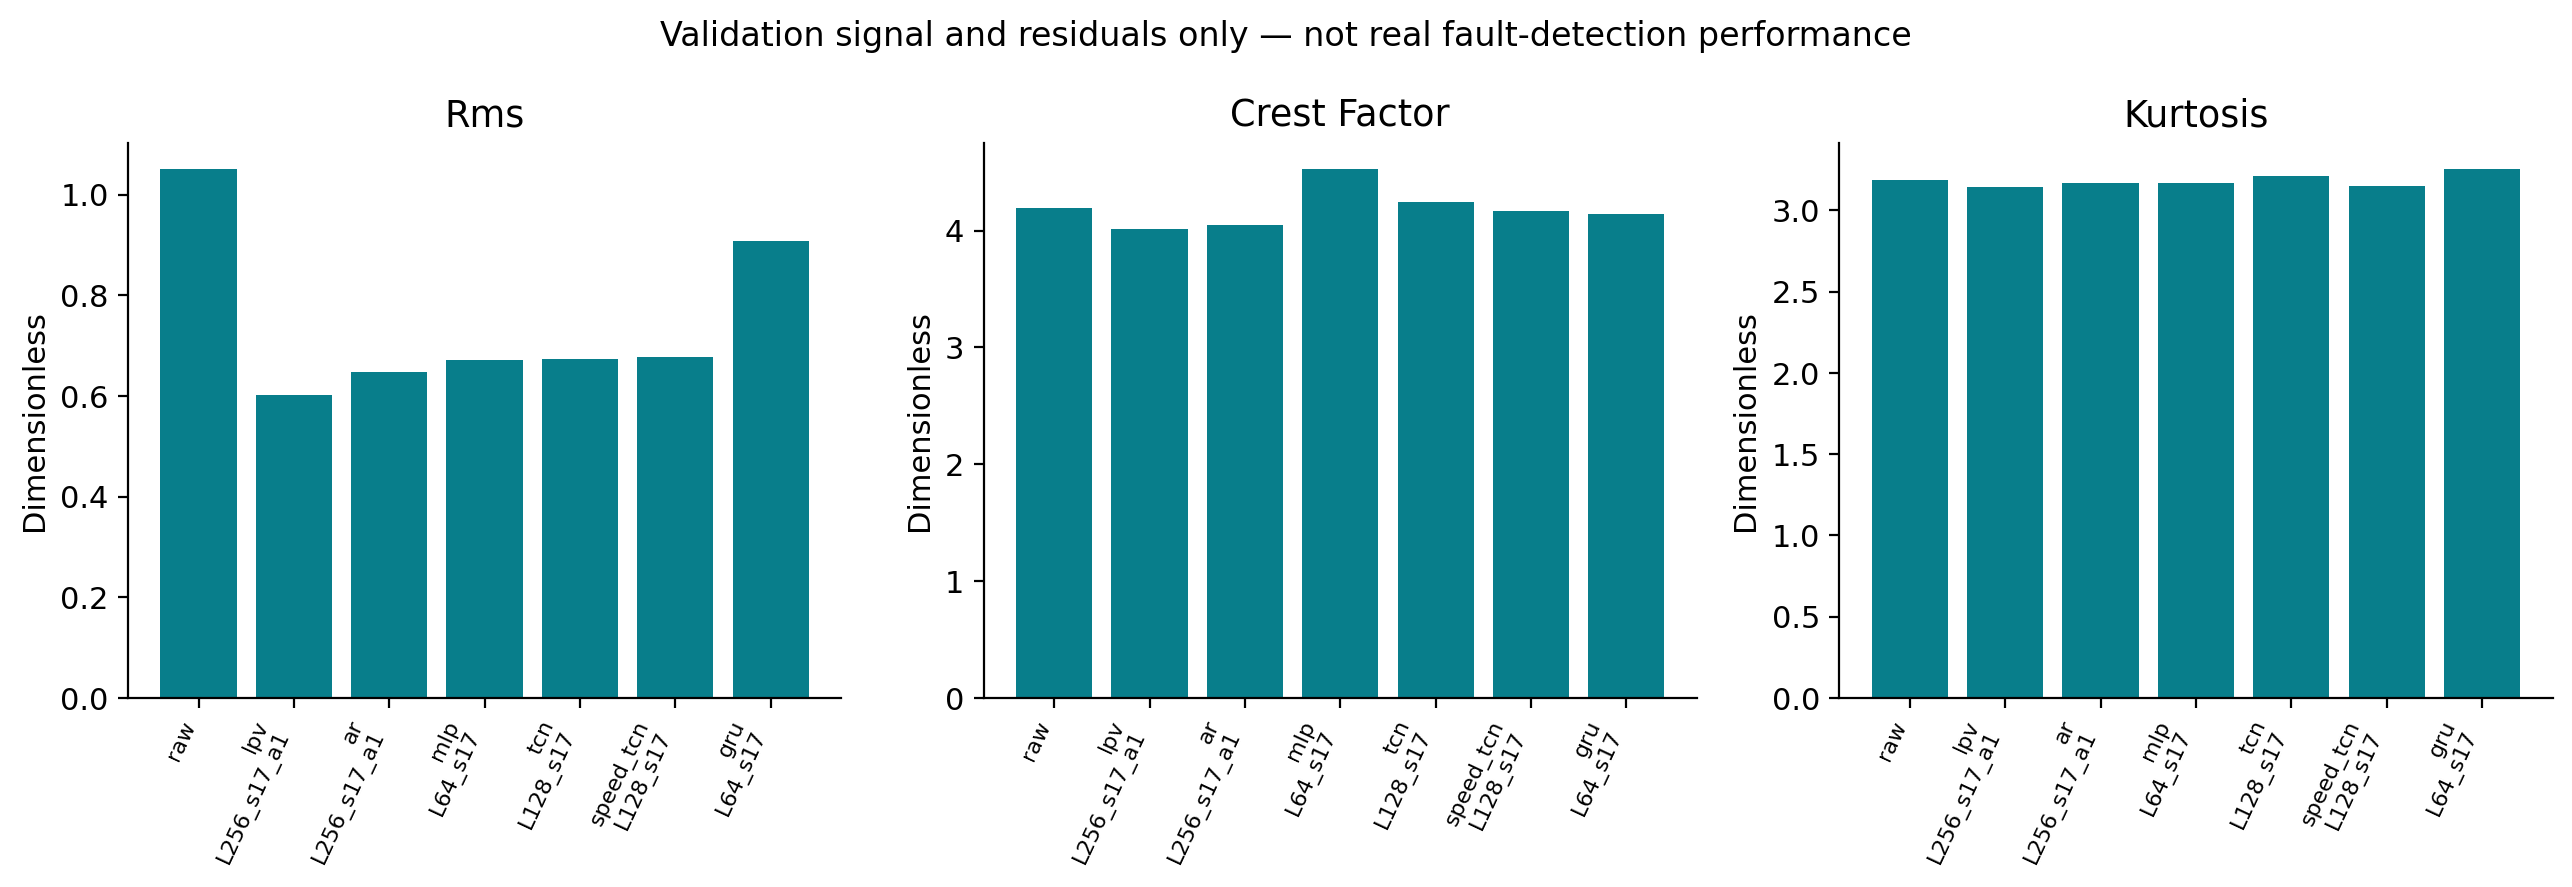

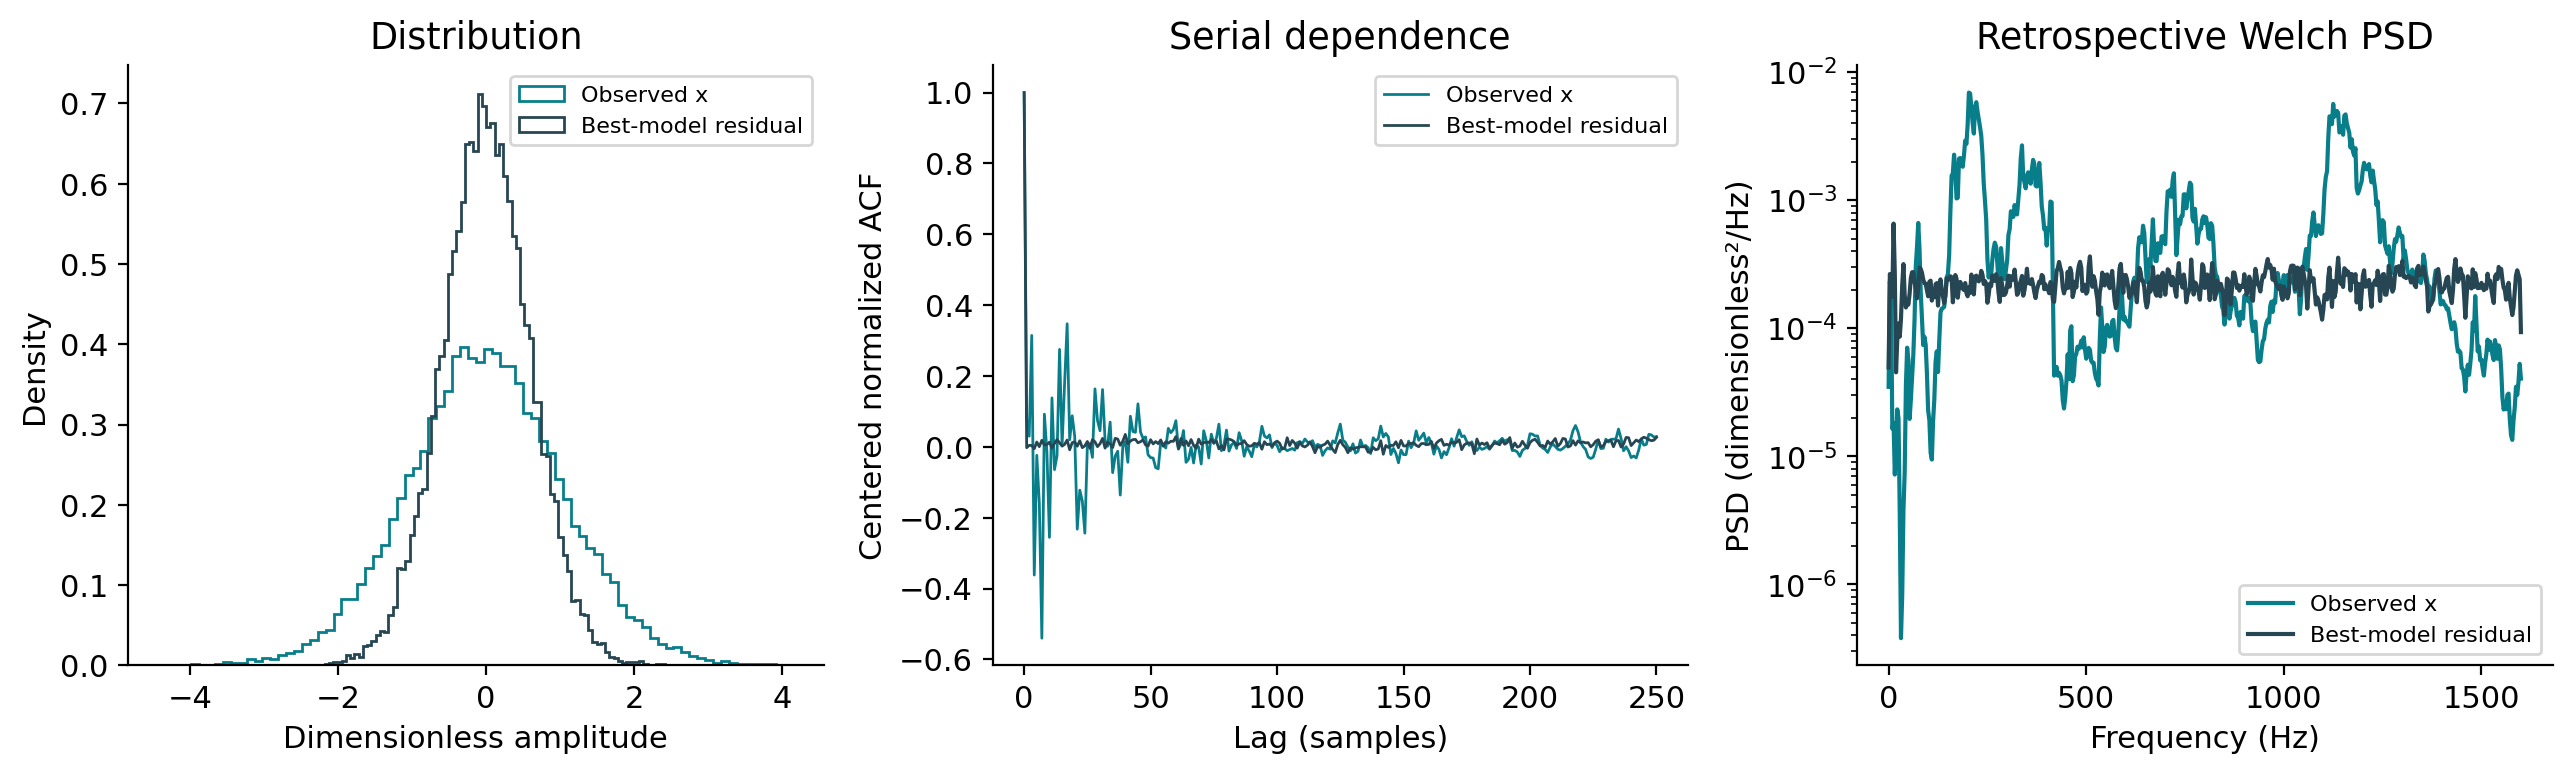

In [18]:
from rotmach.diagnostics import signal_features, normalized_acf, correlated_kurtosis, pmi
residual=valid["x"][common]-yhat[common]
display(pd.DataFrame([signal_features(valid["x"][common]), signal_features(residual)],
                     index=["validation supplied x","validation best-model residual"]))
assert np.isclose(signal_features(residual)["rms"]**2, measured["mse"])
display(Image(filename=str(ROOT / "reports/figures/residual_features.png"), width=1100))
display(Image(filename=str(ROOT / "reports/figures/residual_structure.png"), width=1100))

### Serial correlation changes what an error bar can mean

23,744 overlapping validation targets are not 23,744 independent machine trials.
A block bootstrap can describe variation along this particular trace. It cannot
supply independent machine-to-machine confidence. Here is an explicit paired
block resampling illustration for the best model's squared errors; its block
length is an analytical sensitivity choice, not an established physical correlation
length. Compare several block lengths and distinguish this from seed variability.

In [19]:
errors=residual**2
rng=np.random.default_rng(2026)
bootstrap=[]
for block_len in [128, 512, 1024]:
    blocks=[errors[i:i+block_len] for i in range(0,len(errors)-block_len+1,block_len)]
    block_means=np.array([b.mean() for b in blocks])
    draws=rng.choice(block_means,size=(500,len(block_means)),replace=True).mean(axis=1)
    bootstrap.append(dict(block_samples=block_len,blocks=len(blocks),
        mean_full_blocks=block_means.mean(),conditional_low=np.quantile(draws,.025),
        conditional_high=np.quantile(draws,.975)))
display(pd.DataFrame(bootstrap))
print("Conditional within-trace bootstrap; incomplete tail block omitted; not population confidence.")

,block_samples,blocks,mean_full_blocks,conditional_low,conditional_high
0,128,185,0.361123,0.348795,0.374235
1,512,46,0.361251,0.339515,0.380721
2,1024,23,0.361251,0.331550,0.388460


Conditional within-trace bootstrap; incomplete tail block omitted; not population confidence.


## 9. Angular resampling and MATLAB-related indicators

A speed number cannot be integrated into shaft cycles until its unit is known.
For RPM, cycles/s is speed/60; for revolutions/s it is speed; for radians/s it is
speed/(2π). Trapezoidal integration gives cumulative cycles, followed by interpolation
onto a uniform cycle grid. Output sample density is **samples/cycle**, not Hz.

The Python routine demands an explicit unit. Its linear interpolation has endpoint
loss and is not anti-alias filtering. The next example is a **synthetic known-speed**
rotation, not a physical-unit claim about the supplied dataset.

samples_per_cycle             128
speed_unit_assumption         rps
total_measured_cycles      11.996
edge_loss_cycles         0.003813
roundtrip_rmse           0.001584
downsampling_warning            1
dtype: object

Synthetic order-3 interpolation RMS difference: 0.00023764582891243883


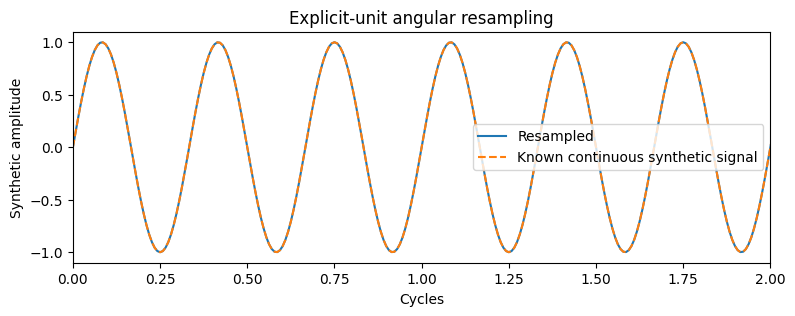

In [20]:
from rotmach.angle_resample import angle_resample
t=np.arange(4000)/1000
speed_rps=2+0.5*t
cycles=2*t+0.25*t*t
rotation_signal=np.sin(2*np.pi*3*cycles)  # known synthetic order 3
angular=angle_resample(rotation_signal,t,speed_rps,unit="rps",samples_per_cycle=128)
display(pd.Series({k:v for k,v in angular.items() if np.isscalar(v)}))
expected=np.sin(2*np.pi*3*angular["cycles"])
print("Synthetic order-3 interpolation RMS difference:",np.sqrt(np.mean((angular["signal"]-expected)**2)))
fig,ax=plt.subplots(figsize=(9,3))
ax.plot(angular["cycles"],angular["signal"],label="Resampled")
ax.plot(angular["cycles"],expected,"--",label="Known continuous synthetic signal")
ax.set(xlim=(0,2),xlabel="Cycles",ylabel="Synthetic amplitude",title="Explicit-unit angular resampling")
ax.legend();plt.show()

### Unit sensitivity is a boundary on interpretation

The following rows apply alternative **assumptions** to the same source speed.
Different cycle counts arise because the interpretations differ dimensionally.
No row is labeled the correct physical interpretation. Consequently downstream
angular PMI on these data would be assumption-conditioned, not verified defect
order evidence. A large output density can oversample interpolation without adding
new physical information.

In [21]:
sensitivity=[]
for assumed in ["rpm","rps","rad_s"]:
    a=angle_resample(valid["x"][common], valid["t"][common], valid["spd"][common],
                     unit=assumed,samples_per_cycle=32)
    sensitivity.append(dict(assumed_unit=assumed,total_cycles=a["total_measured_cycles"],
        output_samples=len(a["signal"]),samples_per_cycle=32,
        interpolation_roundtrip_rmse=a["roundtrip_rmse"],
        downsampling_warning=a["downsampling_warning"]))
display(pd.DataFrame(sensitivity))

,assumed_unit,total_cycles,output_samples,samples_per_cycle,interpolation_roundtrip_rmse,downsampling_warning
0,rpm,18.264457,585,32,1.247178,1
1,rps,1095.867392,35068,32,0.301209,0
2,rad_s,174.412712,5582,32,0.957912,1


### Correlated kurtosis (CK)

The reference's exact formula is
\[
CK_M(T)=\frac{\sum_n[\prod_{m=0}^{M}y_{n-mT}]^2}
{(\sum_n y_n^2)^{M+1}},\qquad y_k=0\text{ for }k<0.
\]
T is an **integer sample lag**. Padding and segment length matter. The original
MATLAB allocates M columns but writes M+1; Python implements the full expression
explicitly. For y=[1,2,3], T=1, M=1, numerator is 0+4+36=40 and denominator is
(1+4+9)²=196, so CK=40/196. Zero energy is undefined.

In [22]:
ck=correlated_kurtosis(np.array([1.,2.,3.]),1,1)
print("Hand-check CK:",ck," expected:",40/196)
assert np.isclose(ck,40/196)
assert np.isnan(correlated_kurtosis(np.zeros(10),1,1))

Hand-check CK: 0.2040816326530612  expected: 0.20408163265306123


### Envelope autocorrelation and PMI

The analytic envelope is derived from the Hilbert transform; its FFT implementation
has record-edge effects and is retrospective. The normalized ACF uses a common
centered-energy denominator, with lag zero at array element zero. PMI transforms
a selected envelope correlation as \(\rho/(1-\rho)\); near-unit rho is unstable,
negative values are retained, and no arbitrary clipping fabricates stability.

The MATLAB coarse selection `acf(round(fs/f_fault))` uses one-based indexing,
so it selects zero-based lag period−1. The corrected implementation selects lag
period. The source's returned `timeindex` has an additional offset. Both branches
are explicitly labeled; numerical identity with a live MATLAB toolbox was **not**
verified. A periodic synthetic amplitude modulation demonstrates the difference.

In [23]:
n=np.arange(8192)
synthetic=(1+0.7*np.cos(2*np.pi*n/64))*np.cos(2*np.pi*n/8)
rows=[]
for variant in ["faithful_reference","scientifically_corrected"]:
    result=pmi(synthetic,samples_per_unit=64,fault_order=1,variant=variant,
               envelope_convention="hilbert")
    rows.append(result)
display(pd.DataFrame(rows))
assert rows[0]["selected_lag_samples"]==63
assert rows[1]["selected_lag_samples"]==64
print("Synthetic modulation validates lag semantics; it is not a real fault detection score.")

,pmi,rho,selected_lag_samples,expected_period_samples,source_timeindex_matlab,variant,status,envelope_convention
0,79.990094,0.987653,63,64,65.0,faithful_reference,ok,hilbert
1,127.000000,0.992187,64,64,NaN,scientifically_corrected,ok,hilbert


Synthetic modulation validates lag semantics; it is not a real fault detection score.


## 10. Full 200-record fault-candidate analysis

The original monolithic upload could not be transferred, but all 20 subsequently
supplied complete-record MATLAB parts are now accessible. The source manifest
describes a lossless struct partition with 10 records per part. The loader verifies
part checksums, ordering, global record identities and logical-data integrity.
Each of the 200 records remains an independent 32,000-sample, 3,200-Hz recording;
the analysis never invents transitions between recording 1's end and recording 2's
beginning. There are 6.4 million vibration samples before common burn-in.

These are **fault-candidate provenance IDs**, not verified health labels. The eight
source fields contain no independently confirmed crack state, onset or severity.
The existing `x` is reused directly; its unavailable `xraw` is not reconstructed
and it is not standardized a second time.

In [24]:
from rotmach.fault_io import verify_fault_parts, iter_fault_records
parts_dir=ROOT / "data/raw/sigfault1_parts"
fault_verification=verify_fault_parts(parts_dir)
part_manifest=json.loads((parts_dir / "manifest.json").read_text())
assert part_manifest["record_total"]==200 and part_manifest["part_total"]==20
print("PASS: complete fault-part verification returned without integrity errors.")
display(pd.DataFrame(part_manifest["parts"])[["filename","record_start_1based",
    "record_end_1based_inclusive","record_count","sha256"]])
display(pd.Series({k:v for k,v in fault_verification.items() if np.isscalar(v)}))
fault_audit=pd.read_csv(ROOT / "reports/fault_data_audit.csv")
assert len(fault_audit)==200 and fault_audit.global_record_id.is_unique
assert (fault_audit.N==32000).all() and (fault_audit.fs==3200).all()
assert fault_audit.speed_reconstruction_max_error.max()<1e-10
assert not fault_audit.has_xraw.any()
display(fault_audit[["x_std","speed_min","speed_max","spdnorm_min","spdnorm_max",
                    "speed_outside_reference_fraction"]].describe())
print("Fault x has no xraw field and is never re-standardized; spdnorm is not clipped.")

PASS: complete fault-part verification returned without integrity errors.


,filename,record_start_1based,record_end_1based_inclusive,record_count,sha256
0,sigfault1_part_001.mat,1,10,10,a5554e18ff68f8fe50b48d6020ea818d279aa7ceed1f55...
1,sigfault1_part_002.mat,11,20,10,a1d96948943512734ad5779dd2acfa2d9e0cfdcfa88702...
2,sigfault1_part_003.mat,21,30,10,f1cccc900b8b0a0cd29e0deed493dee367ed963484ee08...
3,sigfault1_part_004.mat,31,40,10,b9f5d5763838dda8770e1dc4bcf250b2698fcd95e4ad54...
4,sigfault1_part_005.mat,41,50,10,b133ebde2b89248dc1851bbfc484bc76d5a28a03703675...
5,sigfault1_part_006.mat,51,60,10,0e085b9c47ce187d561082550a3bb39bd1555eeaf3676a...
6,sigfault1_part_007.mat,61,70,10,a0cf55f56547c1eb80525b138161f465dbaac2280a5e11...
7,sigfault1_part_008.mat,71,80,10,ec7bc802d52fec5513beafb5363ff4ded6324974ab1cb2...
8,sigfault1_part_009.mat,81,90,10,8544d50c12df5bdabfbb99f5deac60c0bf540ec231e59b...
9,sigfault1_part_010.mat,91,100,10,2009abd91fc96912085f09fb73cf185a09782183247d97...


status                                                                                PASS
part_total                                                                              20
record_total                                                                           200
logical_data_sha256                      705731dbfe79605f9ef10de1146c99cc2db95e85ab9f3b...
manifest_sha256                          723aed22fa08aaf138139b5a4a2872e9e88944037d50cc...
original_file_sha256_declared            abc20abd79660b502750b747815e2b96825c0fd6982c72...
original_file_independently_available                                                False
provenance_limit                         Original MAT fingerprint is declared by the su...
dtype: object

,x_std,speed_min,speed_max,spdnorm_min,spdnorm_max,speed_outside_reference_fraction
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,1.065039,124.242580,167.352253,0.003884,1.000337,0.006225
std,0.075331,0.117844,0.022739,0.002724,0.000526,0.004638
min,0.944426,123.655276,167.293628,-0.009691,0.998982,0.000000
25%,0.992013,124.192271,167.338419,0.002721,1.000018,0.002711
50%,1.051408,124.297674,167.350700,0.005157,1.000301,0.006391
75%,1.139657,124.320664,167.365209,0.005689,1.000637,0.009352
max,1.190128,124.389549,167.416491,0.007281,1.001822,0.024969


Fault x has no xraw field and is never re-standardized; spdnorm is not clipped.


### Boundary and coverage checks on the full result tables

The saved long-format table contains one row per recording and model, plus raw
signal rows. Every model must cover the same 200 provenance IDs and use exactly
31,744 target samples after excluding the first 256 observations of each record.
This guarantees equal segment lengths and prevents CK or RMS comparisons from
being driven merely by different warm-up exclusions.

Model checkpoints remain fitted on the original reference training record. The
fault-candidate data did not tune, refit, or select the validation winner. Teacher
forcing nevertheless gives each model previous observations of the current
candidate record, so predictable defect content could be removed from residuals.

In [25]:
fault_rows=pd.read_csv(ROOT / "reports/fault_record_features.csv")
assert not fault_rows.duplicated(["record_id","model_id"]).any()
assert (fault_rows.n_evaluated==32000-256).all()
assert (fault_rows.burnin_samples==256).all()
coverage=fault_rows.groupby("model_id").agg(records=("record_id","nunique"),
    rows=("record_id","size"),minimum_samples=("n_evaluated","min"))
assert (coverage.records==200).all()
assert set(pd.to_numeric(fault_rows.record_id))==set(range(1,201))
display(coverage)
print("Total time-domain feature rows:",len(fault_rows))
print("No record-index split is interpreted as ground-truth healthy/faulty classes.")

,records,rows,minimum_samples
model_id,,,
ar_L256_s17_a1,200,200,31744
arx_L256_s17_a1,200,200,31744
capacity_tcn_L64_s17,200,200,31744
gru_L64_s17,200,200,31744
late_tcn_L64_s17,200,200,31744
lpv_L256_s17_a1,200,200,31744
mean_L256_s17,200,200,31744
mlp_L64_s17,200,200,31744
ols_L256_s17,200,200,31744


Total time-domain feature rows: 2800
No record-index split is interpreted as ground-truth healthy/faulty classes.


### Recompute a neutrally selected real record

Record 1 is selected **by fixed index**, before viewing its feature magnitude.
The notebook verifies its arrays and reloads the provisional validation-best
checkpoint. It recomputes RMS, crest factor and kurtosis on the same target segment
and compares them with the full-study CSV. This inexpensive cross-check exercises
the actual fault-data → model → residual → feature path. The full 200-record suite
can be rerun explicitly with the CLI; routine notebook execution does not repeat
every costly model/record/angle combination.

In [26]:
from itertools import islice
fault_record=next(iter_fault_records(parts_dir,verify=False))
assert fault_record["N"]==32000 and fault_record["fs"]==3200
assert set(["t","fs","N","spd","spdnorm","x","spdmin","spdmax"]).issubset(fault_record)
assert len(fault_record["x"])==len(fault_record["spd"])==len(fault_record["t"])==32000
print("First real record fields:",sorted(fault_record))
print("Measured first/last timestamp:",fault_record["t"][0],fault_record["t"][-1])
fault_prediction=load_model_and_predict(ROOT,best_id,fault_record)
fault_residual=fault_record["x"][256:]-fault_prediction[256:]
computed_fault_features=signal_features(fault_residual)
stored_fault_row=fault_rows[(pd.to_numeric(fault_rows.record_id)==1)&
                           (fault_rows.model_id==best_id)].iloc[0]
for feature,value in computed_fault_features.items():
    assert np.isclose(value,stored_fault_row[feature],rtol=1e-5,atol=1e-7),feature
display(pd.DataFrame({"recomputed":computed_fault_features,
                     "full_study_csv":{k:stored_fault_row[k] for k in computed_fault_features}}))
print("PASS: real record-1 checkpoint residual features match the full 200-record study.")

First real record fields: ['N', 'fs', 'global_record_id', 'record_id', 'source_logical_sha256', 'source_part', 'source_part_sha256', 'spd', 'spdmax', 'spdmin', 'spdnorm', 't', 'x']
Measured first/last timestamp: 0.0003125 10.0


,recomputed,full_study_csv
rms,0.614289,0.614289
crest_factor,4.790966,4.790966
kurtosis,3.250773,3.250773


PASS: real record-1 checkpoint residual features match the full 200-record study.


### Record-wise trends and descriptive distributions

The plots compare raw signals with residual statistics across all recording IDs.
They show observable changes and model-dependent amplification or attenuation;
they do not identify crack onset or severity. A model may reduce RMS while
increasing crest factor, since RMS measures average energy while crest factor
measures the largest amplitude relative to average energy. Kurtosis can increase
because a small number of extreme observations dominate the fourth moment.

Global index preserves supplied order only. Any visible trend or discontinuity
requires independent experimental metadata before it becomes a fault-state claim.
Equal burn-in and normalization help comparison but do not create missing labels.

rms                     crest_factor  \
                                     median       min       max       median   
kind         model_id                                                          
ar           ar_L256_s17_a1        0.665676  0.590948  0.738946     4.818784   
arx          arx_L256_s17_a1       0.666277  0.591570  0.739836     4.812602   
capacity_tcn capacity_tcn_L64_s17  0.695132  0.608082  0.773394     4.858827   
gru          gru_L64_s17           0.913906  0.810479  1.060294     5.011131   
late_tcn     late_tcn_L64_s17      0.688605  0.606192  0.767319     4.868368   
lpv          lpv_L256_s17_a1       0.623974  0.556501  0.692751     4.908411   
mean         mean_L256_s17         1.053415  0.946470  1.191454     4.814454   
mlp          mlp_L64_s17           0.681743  0.600911  0.762943     4.795177   
ols          ols_L256_s17          0.665687  0.590974  0.738955     4.818087   
persistence  persistence_L256_s17  1.493909  1.288587  1.811555     5.118118   
raw          raw                   1.053410  0.946469  1.191579     4.814118   
speed_tcn    speed_tcn_L128_s17    0.680298  0.603588  0.766843     4.826195   
tcn          tcn_L128_s17          0.681158  0.602607  0.760358     4.844180   
zero         zero_L256_s17         1.053410  0.946469  1.191579     4.814118   

                                                       kurtosis            \
                                        min       max    median       min   
kind         model_id                                                       
ar           ar_L256_s17_a1        4.158635  6.745084  3.295679  3.122968   
arx          arx_L256_s17_a1       4.161848  6.692362  3.298296  3.116706   
capacity_tcn capacity_tcn_L64_s17  4.042726  6.257349  3.292343  3.099419   
gru          gru_L64_s17           4.051278  7.544614  3.412047  3.184490   
late_tcn     late_tcn_L64_s17      4.201137  6.200920  3.304069  3.084992   
lpv          lpv_L256_s17_a1       4.074789  6.622693  3.272660  3.080788   
mean         mean_L256_s17         4.137960  7.148874  3.391280  3.193002   
mlp          mlp_L64_s17           4.182762  6.173051  3.277209  3.115257   
ols          ols_L256_s17          4.157682  6.745822  3.295630  3.122902   
persistence  persistence_L256_s17  4.327921  7.096463  3.562371  3.208172   
raw          raw                   4.140948  7.145969  3.391280  3.193002   
speed_tcn    speed_tcn_L128_s17    4.219719  6.368702  3.289983  3.095010   
tcn          tcn_L128_s17          4.224469  6.586377  3.322133  3.130355   
zero         zero_L256_s17         4.140948  7.145969  3.391280  3.193002   

                                             
                                        max  
kind         model_id                        
ar           ar_L256_s17_a1        3.498118  
arx          arx_L256_s17_a1       3.484372  
capacity_tcn capacity_tcn_L64_s17  3.510831  
gru          gru_L64_s17           3.852173  
late_tcn     late_tcn_L64_s17      3.508626  
lpv          lpv_L256_s17_a1       3.491986  
mean         mean_L256_s17         3.806269  
mlp          mlp_L64_s17           3.477520  
ols          ols_L256_s17          3.498068  
persistence  persistence_L256_s17  4.233107  
raw          raw                   3.806269  
speed_tcn    speed_tcn_L128_s17    3.458002  
tcn          tcn_L128_s17          3.552062  
zero         zero_L256_s17         3.806269

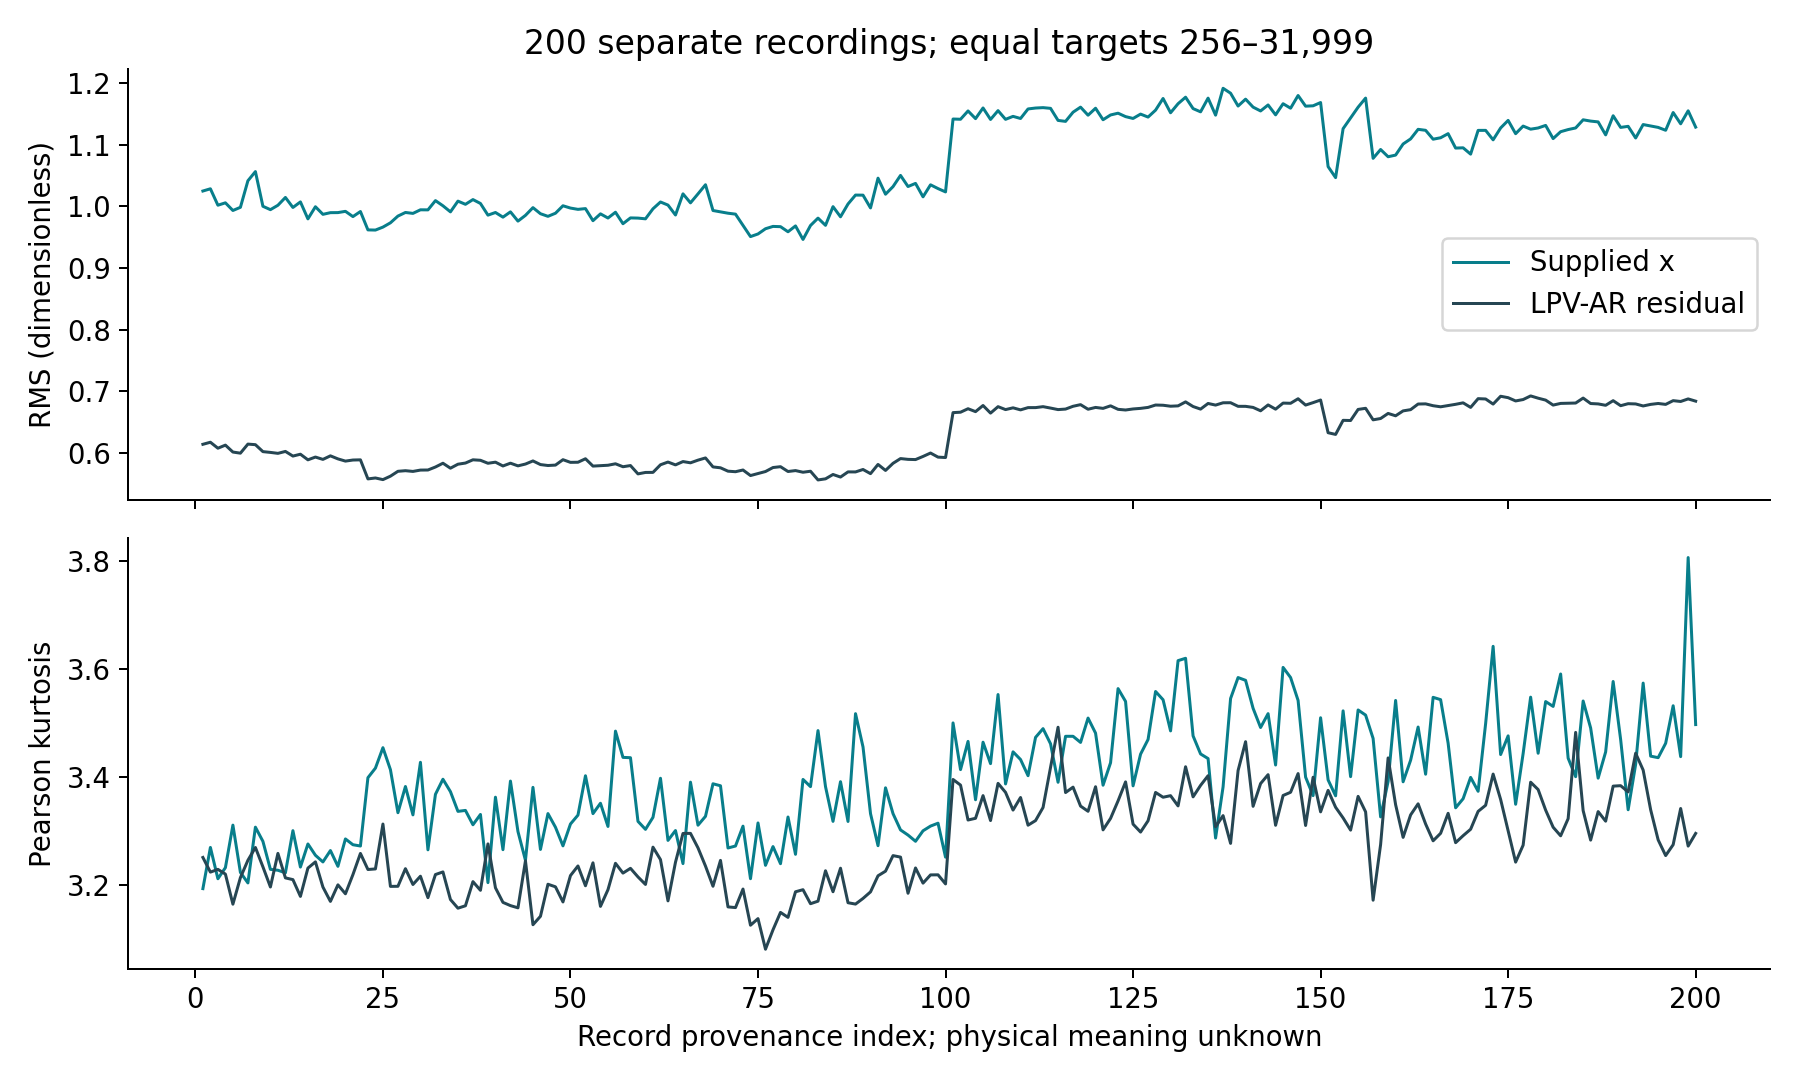

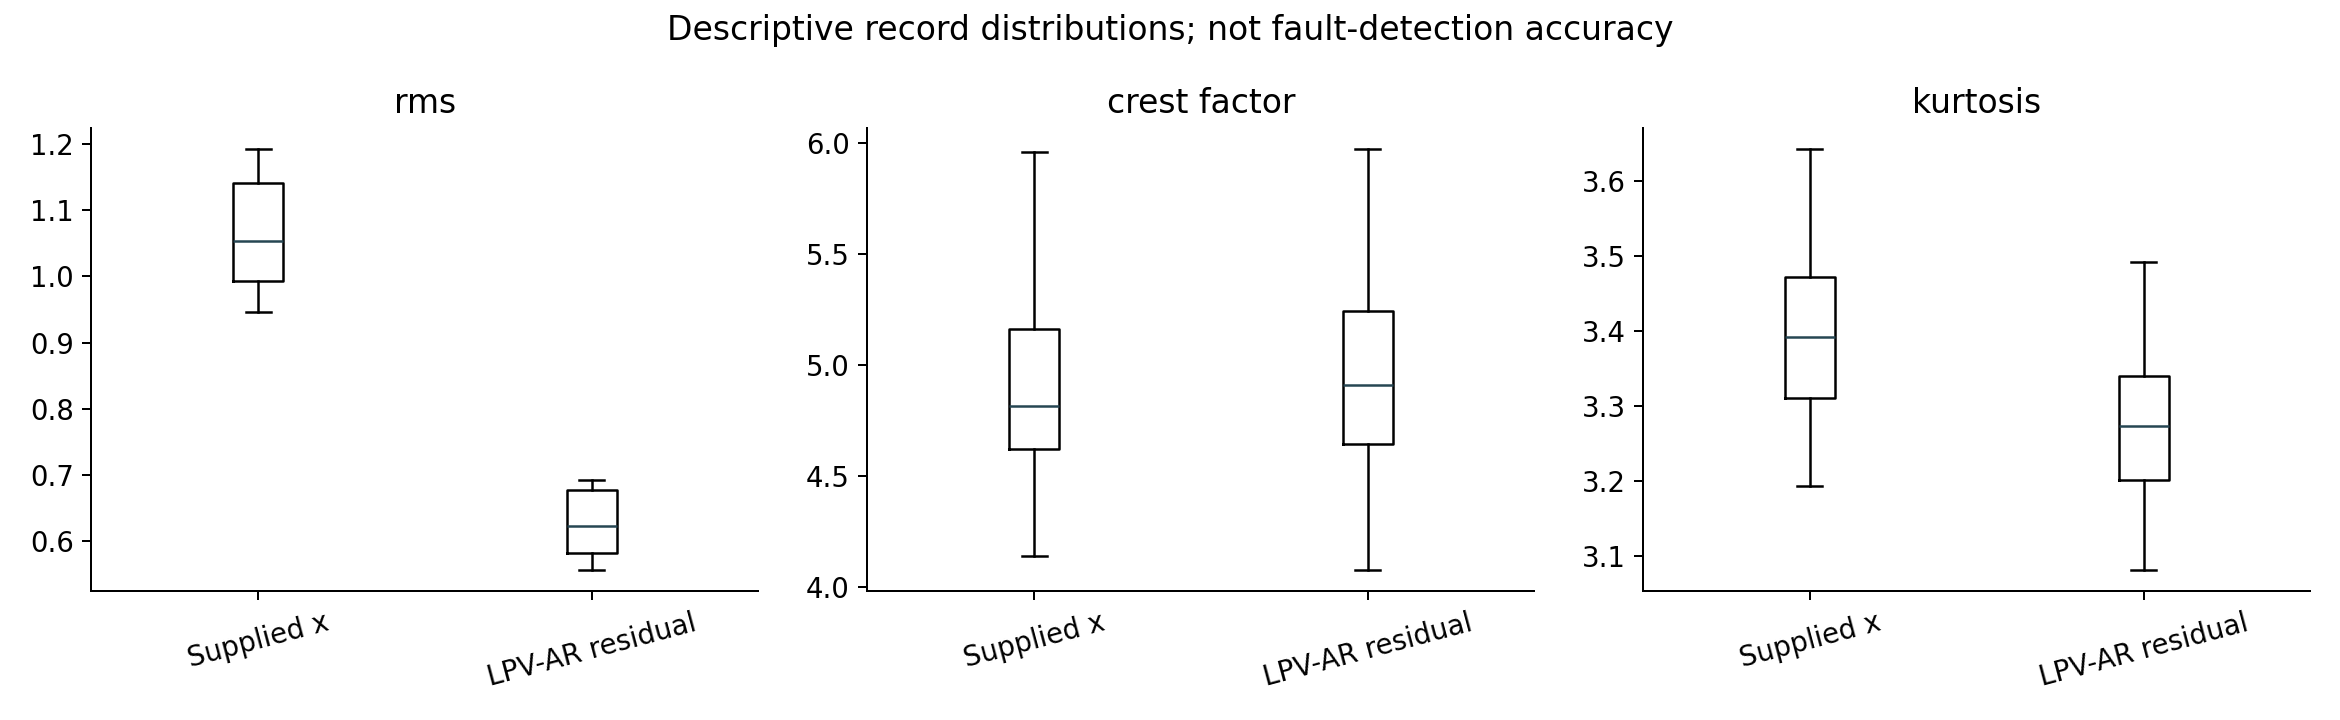

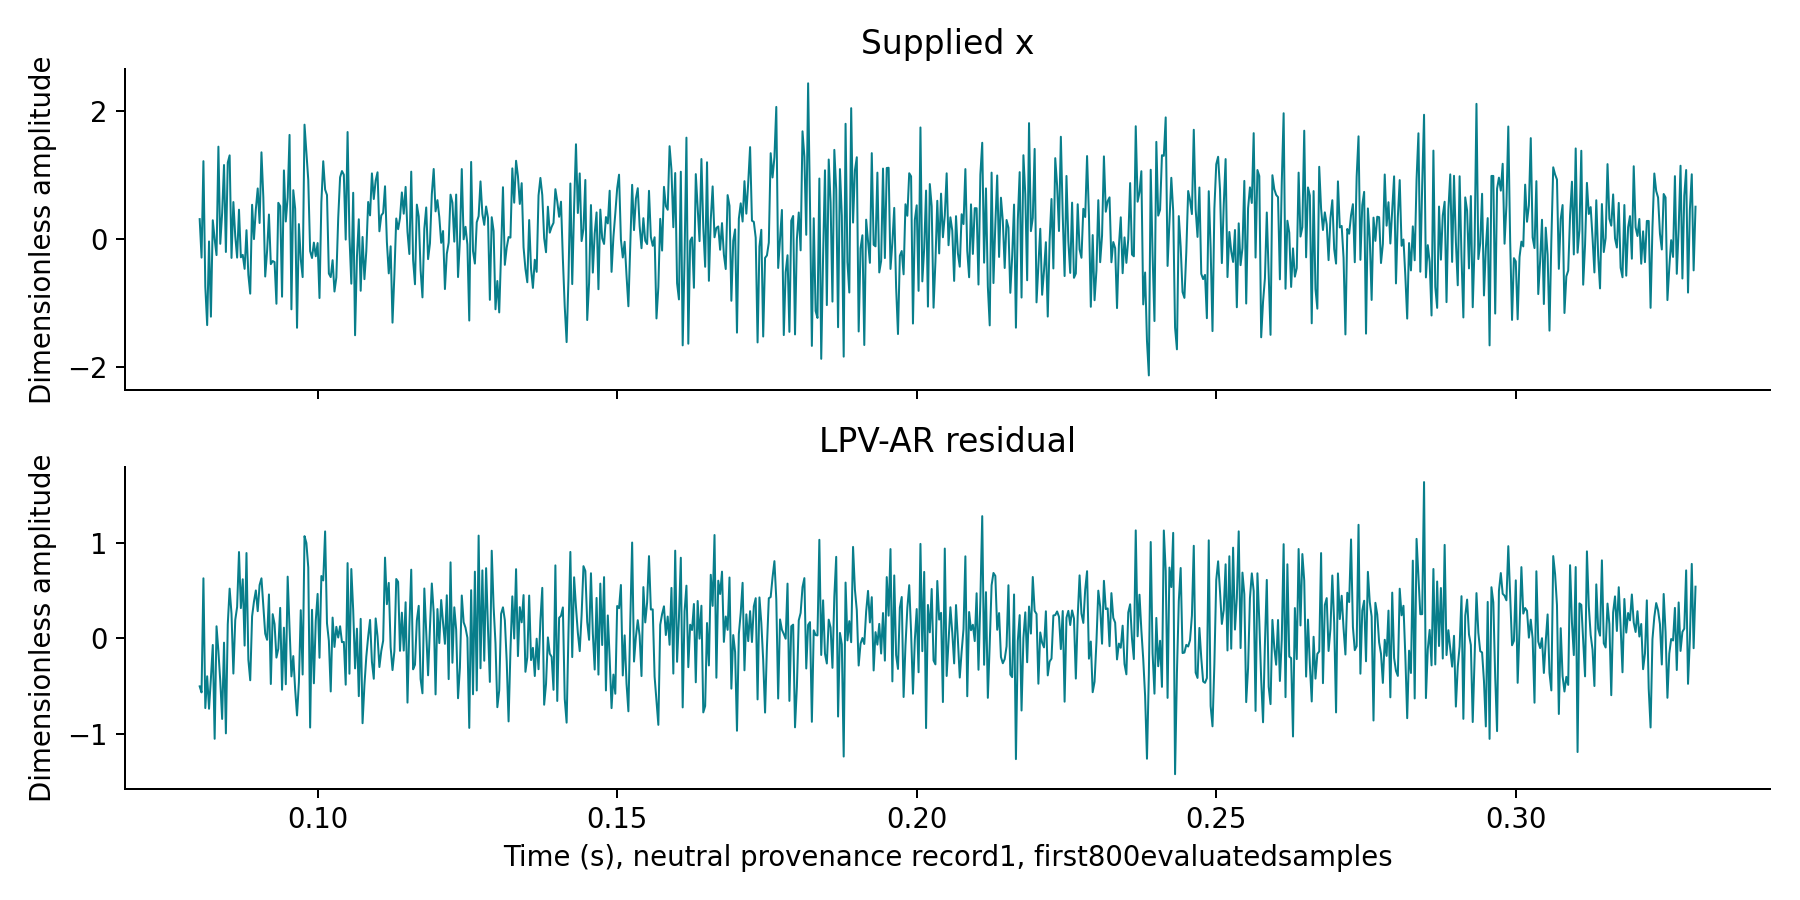

In [27]:
fault_summary=fault_rows.groupby(["kind","model_id"])[["rms","crest_factor","kurtosis"]].agg(["median","min","max"])
display(fault_summary)
display(Image(filename=str(ROOT / "reports/figures/fault_rms_trends.png"),width=1100))
display(Image(filename=str(ROOT / "reports/figures/fault_indicator_distributions.png"),width=1100))
display(Image(filename=str(ROOT / "reports/figures/fault_neutral_record_overlay.png"),width=1100))

### Prediction quality and diagnostic quality have different objectives

Validation MSE measures reference-condition one-step prediction. Candidate-record
RMS/crest/kurtosis/CK/PMI describe residual structure. Comparing their rankings is
informative, but a high indicator is not automatically a good detector. It might
reflect operating speed, interpolation, nonstationary reference variation,
recording length or model mismatch rather than a physical defect.

Use the trade-off figure to ask whether lower validation MSE consistently produces
a stronger descriptive indicator. An inconclusive or conflicting ranking is a
scientific result, not something to hide by choosing one favorable metric.

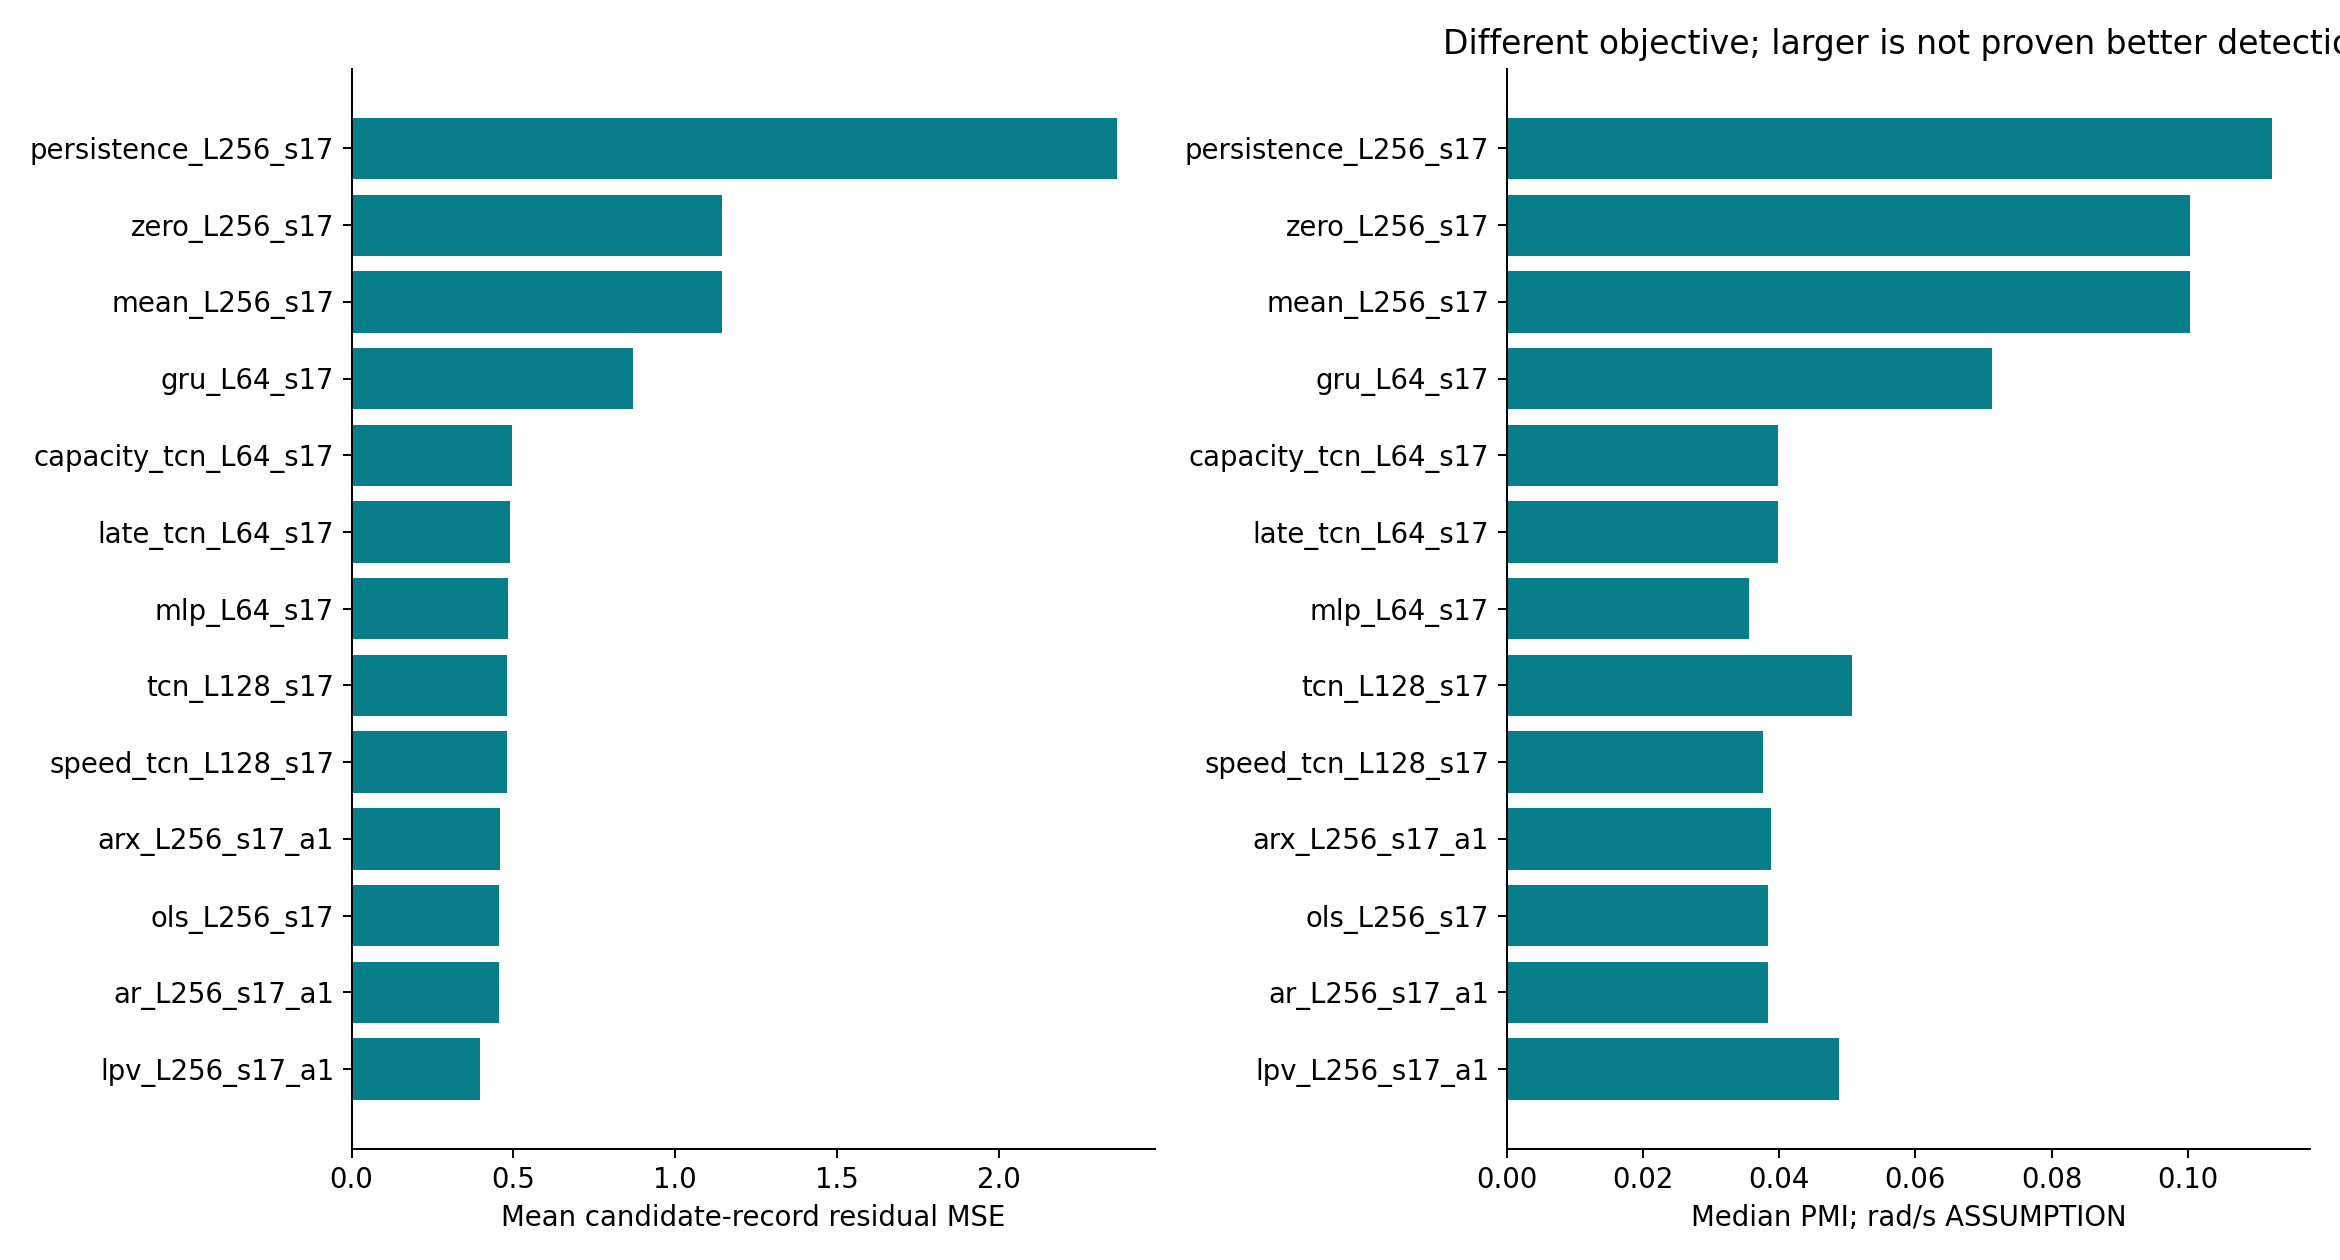

,mean_speed_source_units,rms,crest_factor,kurtosis
mean_speed_source_units,1.000000,-0.033752,-0.050645,0.098111
rms,-0.033752,1.000000,0.302222,0.703182
crest_factor,-0.050645,0.302222,1.000000,0.568568
kurtosis,0.098111,0.703182,0.568568,1.000000


In [28]:
display(Image(filename=str(ROOT / "reports/figures/fault_prediction_diagnostic_tradeoff.png"),width=1100))
raw_fault=fault_rows[fault_rows.model_id=="raw"]
display(raw_fault[["mean_speed_source_units","rms","crest_factor","kurtosis"]].corr())

### Angular CK/PMI: real recordings, explicit physical assumptions

The angular table applies declared RPM, revolutions/second, and radians/second
assumptions to the **real** candidate recordings. These are dimensional sensitivity
branches, not three alternative ground truths. Samples/cycle and interpolation
effects are recorded. Both source-indexing and corrected PMI variants are retained.
Report the actual record coverage of each assumption/density combination; never
imply an uncomputed case was evaluated.

The resulting values are measured under each assumption. Without independent
speed-unit and defect-order evidence, none establishes verified shaft-fault order.
Large changes between assumptions or densities indicate sensitivity that limits
physical interpretation, even if a trace looks visually persuasive.

records  rows
model_id             speed_unit_assumption samples_per_cycle               
ar_L256_s17_a1       rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
arx_L256_s17_a1      rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
capacity_tcn_L64_s17 rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
gru_L64_s17          rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
late_tcn_L64_s17     rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
lpv_L256_s17_a1      rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
mean_L256_s17        rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
mlp_L64_s17          rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
ols_L256_s17         rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
persistence_L256_s17 rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
raw                  rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
speed_tcn_L128_s17   rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
tcn_L128_s17         rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200
zero_L256_s17        rad_s                 256                    200   200
                     rpm                   2048                   200   200
                     rps                   32                     200   200

Measured angular feature rows: 8400


,ck_order1,pmi_faithful_reference,pmi_scientifically_corrected
speed_unit_assumption,,,
rad_s,0.000018,0.046478,0.050175
rpm,0.000023,0.095405,0.093495
rps,0.000024,0.059216,0.060219


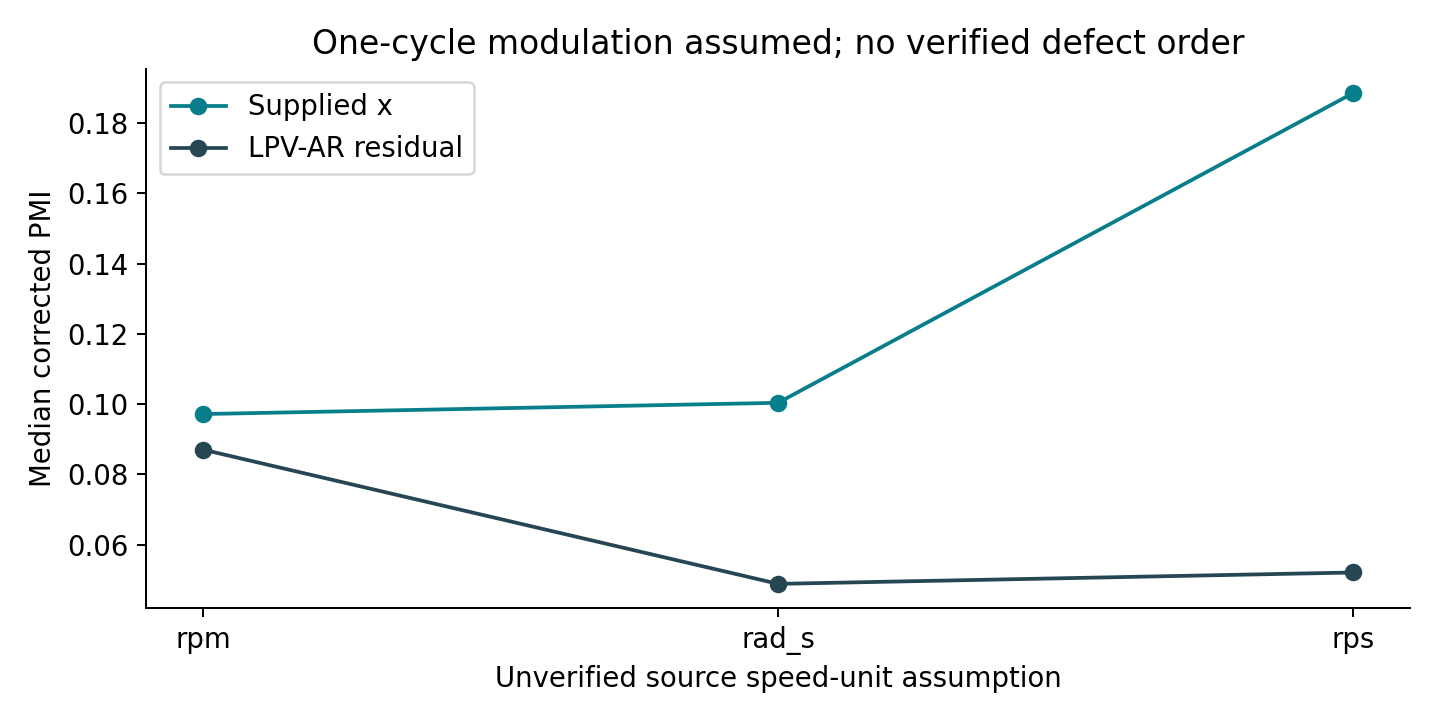

In [29]:
fault_angles=pd.read_csv(ROOT / "reports/fault_angular_features.csv")
angular_coverage=fault_angles.groupby(["model_id","speed_unit_assumption","samples_per_cycle"]).agg(
    records=("record_id","nunique"),rows=("record_id","size"))
display(angular_coverage)
print("Measured angular feature rows:",len(fault_angles))
display(fault_angles.groupby("speed_unit_assumption")[["ck_order1","pmi_faithful_reference",
    "pmi_scientifically_corrected"]].median())
display(Image(filename=str(ROOT / "reports/figures/fault_unit_sensitivity.png"),width=1100))

### Verify angular features and inspect the complete real-signal workflow

The following independent checkpoint path recomputes angular features on the
same fixed real record under all three declared speed interpretations, then
checks the saved study's CK and both PMI variants. This is a numerical consistency
test, not a verification of the unknown physical unit. The workflow figure shows
the residual, uniform-cycle interpolation, envelope, and lag selection on that
record. Its rad/s label remains an explicit **assumption**.

,assumed_unit,samples_per_cycle,angular_n,ck_order1,pmi_faithful_reference,pmi_scientifically_corrected
0,rpm,2048,48548,0.000022,0.069271,0.063519
1,rad_s,256,57950,0.000018,0.032621,0.037591
2,rps,32,45514,0.000022,0.030510,0.027810


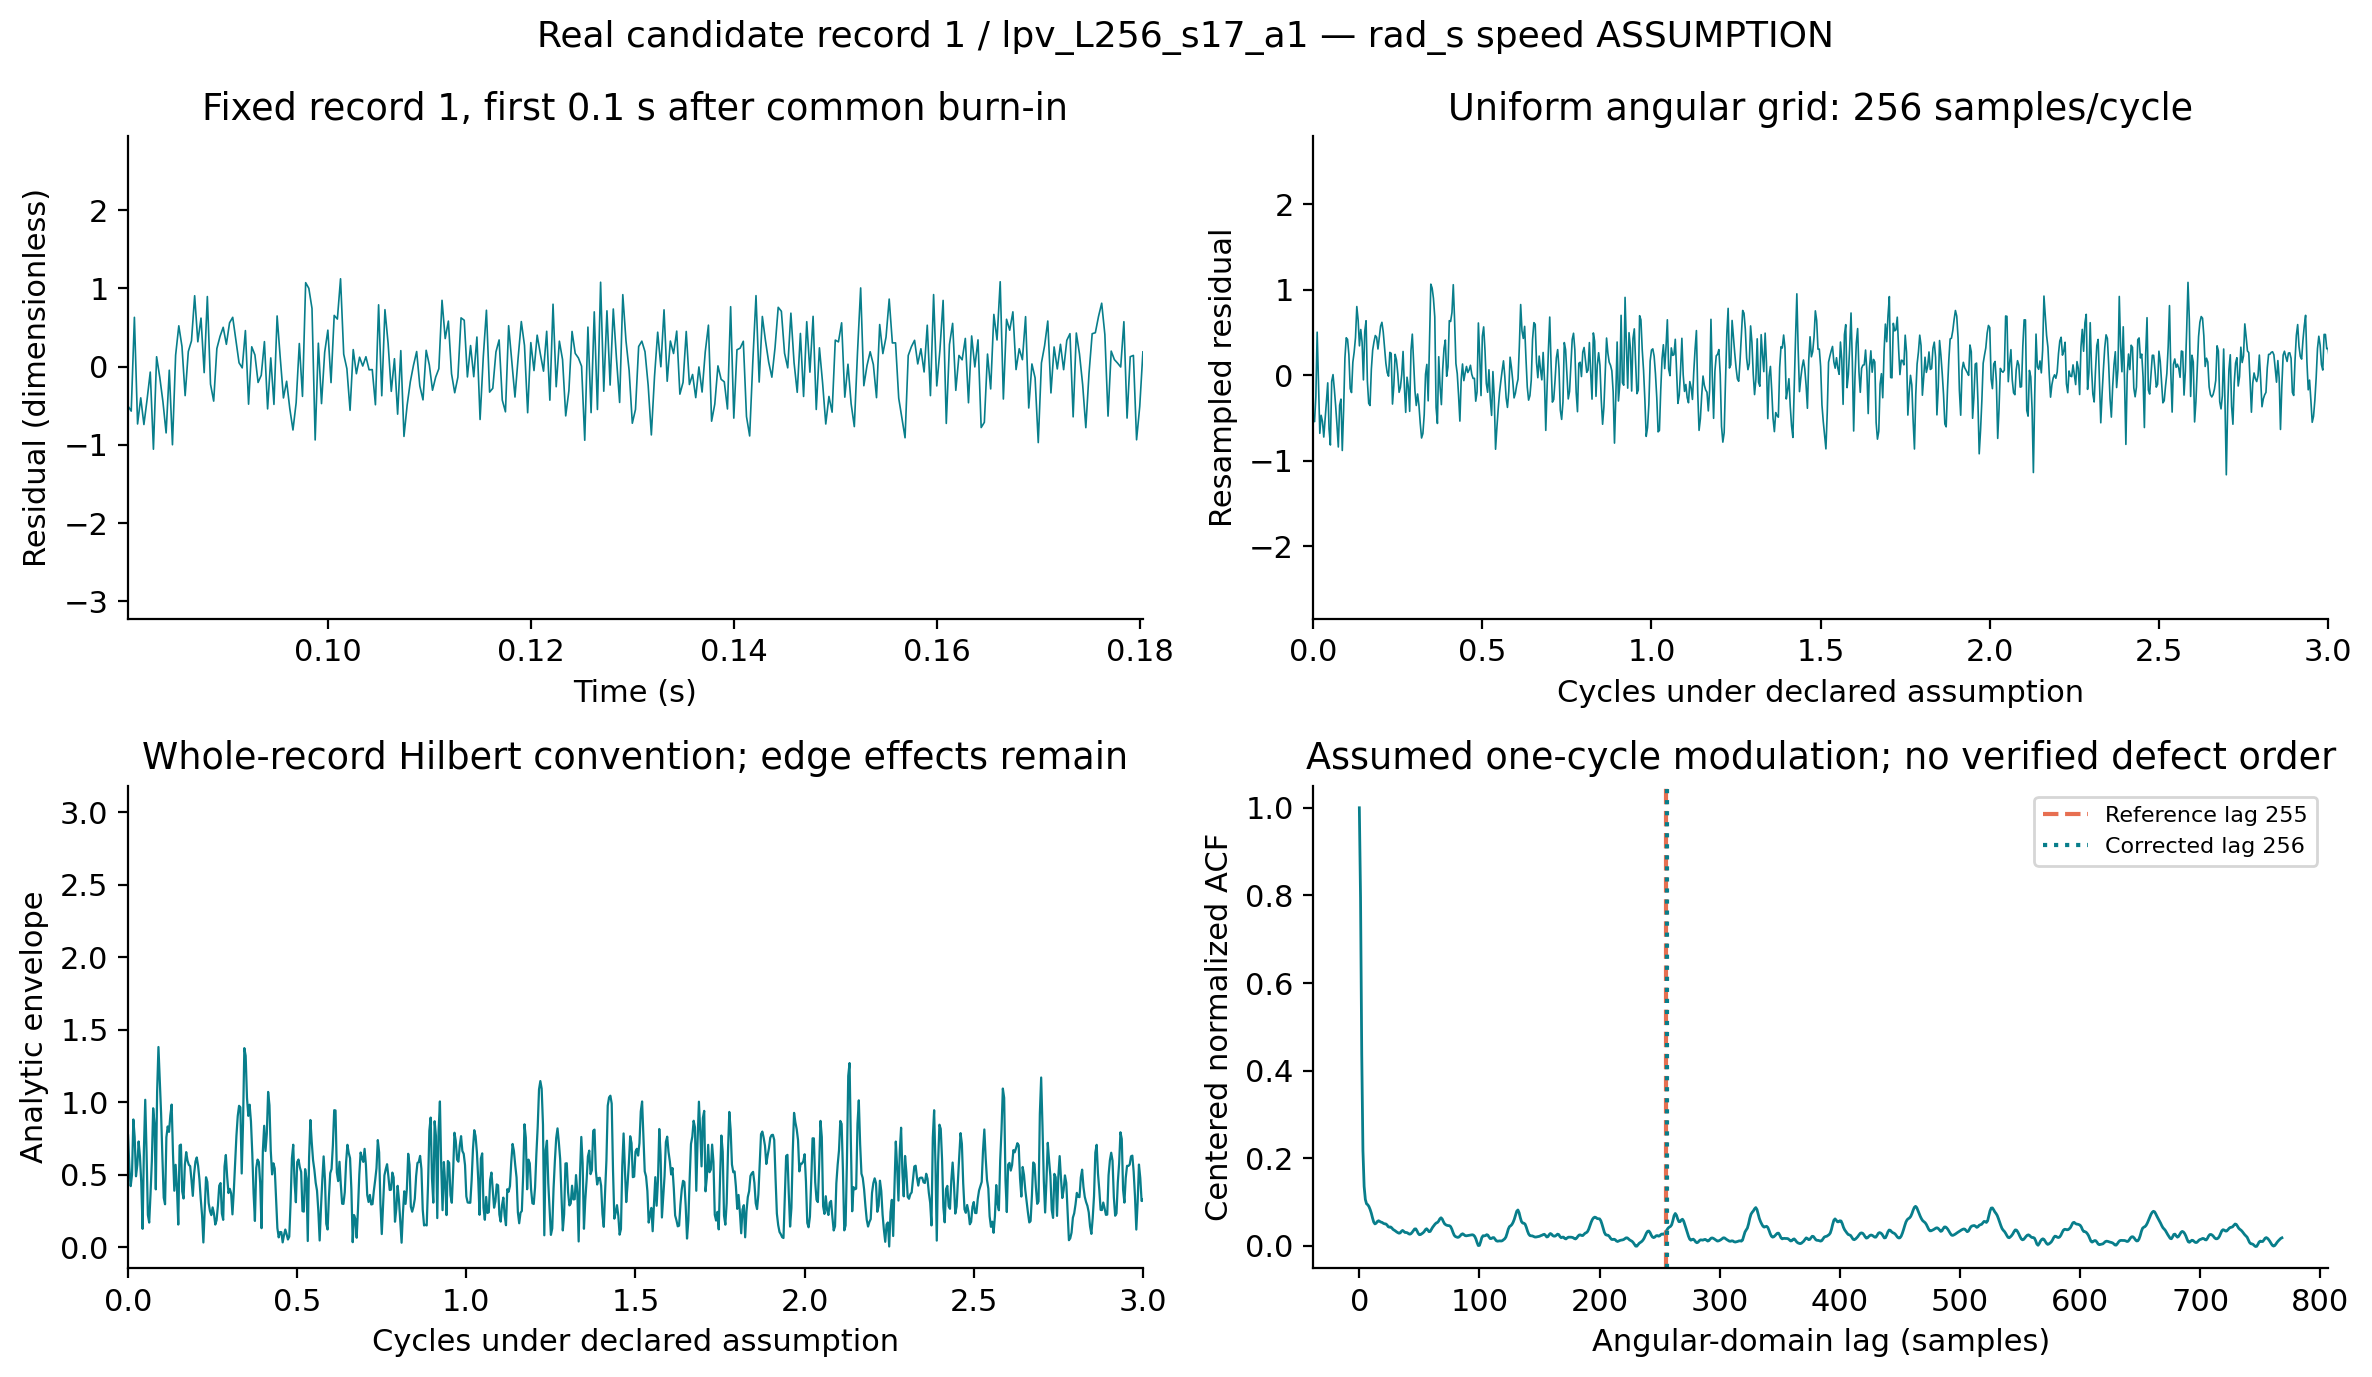

PASS: fixed real record1 angular CK/PMI agrees with saved full-study CSV under each assumption.


In [30]:
from rotmach.fault_study import angular_features
angular_crosschecks=[]
for assumed in ["rpm","rad_s","rps"]:
    recomputed=angular_features(fault_residual,fault_record["t"][256:],
        fault_record["spd"][256:],fault_record["fs"],assumed)
    stored=fault_angles[(pd.to_numeric(fault_angles.record_id)==1)&
        (fault_angles.model_id==best_id)&(fault_angles.speed_unit_assumption==assumed)].iloc[0]
    for feature in ["ck_order1","pmi_faithful_reference","pmi_scientifically_corrected"]:
        assert np.isclose(recomputed[feature],stored[feature],rtol=1e-5,atol=1e-8,equal_nan=True),feature
    angular_crosschecks.append({"assumed_unit":assumed,**{k:recomputed[k] for k in
        ["samples_per_cycle","angular_n","ck_order1","pmi_faithful_reference","pmi_scientifically_corrected"]}})
display(pd.DataFrame(angular_crosschecks))
from rotmach.plots import render_fault_workflow_figure
workflow_figure=render_fault_workflow_figure(ROOT,unit="rad_s")
display(Image(filename=str(workflow_figure),width=1100))
print("PASS: fixed real record1 angular CK/PMI agrees with saved full-study CSV under each assumption.")

### What real data now establish, and what labels would still add

The accessible parts establish the actual 200-record structure and permit full
record-wise raw/residual diagnostics. They resolve the former data-transfer
blocker. They do **not** establish healthy/faulty classes, physical crack onset,
severity, or a true ROC/AUC/F1/sensitivity score. A future label-evaluation branch
requires documented record-level labels and a threshold-selection protocol that
does not use the evaluation records to optimize its own reported performance.
`sigtest.mat` and `sigfault2.mat` remain unavailable.

To rerun the complete candidate-record workflow from the project folder:

```bash
python -m rotmach.cli faults --input data/raw/sigfault1_parts
```

This heavier command uses every verified record; it is separate from the default
notebook's saved-table inspection and one-record numerical cross-check.

### Reproduction and artifact cross-check

The scalar metrics just computed are independently regenerated from a packaged
checkpoint and original validation samples. This is a checkpoint inference
verification, not an independent full retraining. Saved run configurations include
input hashes and seed; `history.csv` records actual epochs. The figure builder can
regenerate every published chart from saved measurements and inputs.

From the project folder:

```bash
python reproduce_minimal.py
python reproduce_all.py --level standard
python reproduce_all.py --level full
python -m pytest -q
```

The standard path reloads artifacts and rebuilds results; the full path retrains.
Linux commands are executed in this environment. PowerShell/macOS instructions
are provided for portability but are not claimed executed on those systems.

In [31]:
# Cross-check the notebook's central number against the official CSV, not a hand-entered constant.
official=results.set_index("run_id").loc[best_id]
assert np.isclose(official.mse,measured["mse"],rtol=1e-6,atol=1e-8)
assert np.array_equal(saved["target_indices"],common)
assert official.n_targets==len(common)
print("PASS: notebook/checkpoint/CSV common-index agreement.")
print("Figure manifest rows:",len(pd.read_csv(ROOT / "reports/figure_manifest.csv")))

PASS: notebook/checkpoint/CSV common-index agreement.
Figure manifest rows: 17


### What this evidence does and does not support

- **Supported:** reproducible, common-index validation comparison on the supplied
  normalized training/validation traces; measured CPU cost; checkpoint round trips;
  controlled speed-conditioning/context/seed investigations; full 200-record
  candidate-fault raw/residual statistics; tested diagnostic formulas and measured
  angular sensitivity under explicit speed-unit assumptions.
- **Conditional:** the selected method is the best **observed validation run** in
  the bounded search, not a guaranteed universally best predictor. Three seeds
  address initialization variability, not population generalization.
- **Blocked:** independent test performance, physical fault classification,
  verified shaft-order PMI, and an exact same-protocol
  benchmark against the lecturer's Spa LPV-ARMA method.

Read the [scientific validity review](../reports/scientific_validity_review.md),
[numerical validation](../reports/numerical_validation.md),
[research evidence log](../research/source_access_log.md), and
[acceptance checklist](../docs/FINAL_ACCEPTANCE_CHECKLIST.md) before making stronger claims.

### Learning checkpoints

1. Why does an L=32 model still start scoring at target 256? **Fair target alignment.**
2. Why is one-step prediction easier than a free-running forecast? **Past true
   observations keep correcting the context.**
3. Why is MSE equal to residual RMS²? **Both average the same squared residuals
   before/after the square root.**
4. Why can a lower MSE fail to improve detection? **Predictable defect content can
   be removed, and no physical labels currently establish diagnostic success.**
5. Why is `samples/cycle` different from Hz? **The independent coordinate is
   rotation, not time; conversion requires independently known speed units.**
6. Why is the best validation MSE not unbiased final evidence? **The same recording
   selected checkpoints and methods. An untouched independent test is still needed.**

## Sources and evidence status

- **Course specification and lecturer anchor:** the supplied updated PDF is the
  authority for the project and rubric. It cites Chen et al., *Mechanical Systems
  and Signal Processing* 224, 112161 (2025),
  [DOI 10.1016/j.ymssp.2024.112161](https://doi.org/10.1016/j.ymssp.2024.112161).
  The citation is course-verified; restricted publisher access prevents an exact
  full-method reproduction or a claimed same-protocol numerical comparison.
- **TCN implementation/method context:**
  [original authors' TCN repository](https://github.com/locuslab/TCN).
  Its original generic sequence tasks are not evidence of gearbox superiority.
- **FiLM conditioning context:**
  [original authors' FiLM repository](https://github.com/ethanjperez/film).
  The speed adaptation here is a project contribution, not a claim that FiLM is new.
- **Executable numerical conventions:** the installed SciPy, scikit-learn and
  PyTorch APIs define the actual algorithms used. Package versions are recorded;
  live MATLAB numerical parity is unverified.
- **Full evidence audit:** [literature matrix](../research/literature_matrix.md)
  and [source access log](../research/source_access_log.md) distinguish original
  source access, documentation, abstracts, and blocked materials.

Every empirical number in this notebook comes from current data, saved artifacts,
or an explicitly synthetic calculation; prior prompt estimates are not results.